# Data-Driven Credit Scoring Using Explainable Machine Learning
**DSE4212/QF4212 Group Project 1 · Group 4 · German Credit Data (UCI Statlog)**

This notebook contains all the code behind the report, in one top-to-bottom run. It cleans and explores the data, engineers features, tunes and evaluates three classifiers (**logistic regression**, **random forest** and **AdaBoost**), explains them with coefficients, permutation importance and SHAP, and audits fairness by gender and age.

**Conventions used throughout**
- Positive class **1 = default / bad credit**, 0 = good credit.
- Misclassification cost **5 × FN + 1 × FP**: approving a defaulter costs five times as much as rejecting a good client (the cost matrix supplied with the dataset).
- One fixed, stratified 80/20 train/test split (seed 4212). The test set is used only for final evaluation.
- Sensitive attributes (gender, age) are never model inputs. They are used only in the fairness audit.

**Contents**
0. Setup
1. Data cleaning and exploratory data analysis
2. Feature engineering
3. Modelling: logistic regression, random forest, AdaBoost
4. Evaluation: operating points and model comparison
5. Interpretation: coefficients, permutation importance, SHAP
6. Fairness analysis
7. Conclusions
8. Business recommendations
9. Saved outputs

**How to run.** Place the notebook next to the `statlog+german+credit+data/` folder and choose *Run All*. Results are written to `outputs/`. The notebook is self-contained: the shared feature-engineering pipeline and evaluation functions are defined in Sections 0.1 and 0.2. Requires scikit-learn ≥ 1.7:

```
pip install pandas numpy matplotlib seaborn "scikit-learn>=1.7" shap joblib
```

## 0. Setup

In [1]:
import sys, json, time, warnings
from pathlib import Path
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import shap

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_curve, roc_auc_score, ConfusionMatrixDisplay
from sklearn.model_selection import (train_test_split, GridSearchCV, RepeatedStratifiedKFold,
                                     StratifiedKFold, cross_val_predict)

# Project root = the folder that contains the data folder (works from the root or a subfolder)
ROOT = Path.cwd() if (Path.cwd() / "statlog+german+credit+data").exists() else Path.cwd().parent

DATA_PATH = ROOT / "statlog+german+credit+data" / "german.data"
OUT = ROOT / "outputs"
FIGURE_DIR = OUT / "figures"
for sub in ("figures", "models", "predictions", "results"):
    (OUT / sub).mkdir(parents=True, exist_ok=True)
if not DATA_PATH.exists():
    raise FileNotFoundError(f"Could not find {DATA_PATH.resolve()}. Run this notebook from the project root.")

TEST_SIZE = 0.20
TARGET = "credit_risk"   # 1 = default (bad), 0 = good
FN_COST = 5              # a missed default costs 5x a wrongly rejected good client


def show_and_save(name):
    plt.savefig(FIGURE_DIR / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close()


sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

### 0.1 Preprocessing
Shared feature engineering and preprocessing, used by every model:
- `FeatureEngineer` builds the eight engineered features and their log transforms. Its 75th-percentile cut-offs are learned in `fit`, i.e. from training data only.
- `make_preprocessor` imputes, one-hot encodes the categoricals and optionally standardises numerics. `make_pipeline` chains both steps with a classifier, so the whole pipeline is refitted inside every cross-validation fold.
- `check_inputs` stops early if expected columns or category labels are missing.

In [2]:
# Libraries
import numpy as np
import pandas as pd
import warnings

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

REQUIRED_COLUMNS = [
    "credit_amount", "duration_months", "employment_since", "savings_account",
    "checking_account", "existing_credits", "other_installment_plans",
    "credit_history",
]

EXPECTED_LABELS = {
    "employment_since": ["Unemployed", "<1 year"],
    "savings_account": ["<100 DM"],
    "checking_account": ["<0 DM"],
    "other_installment_plans": ["No / none"],
    "credit_history": [
        "Past repayment delay",
        "Critical account / other credits elsewhere",
    ],
}


def check_inputs(X):
    """Raise if required columns are missing; warn if an expected label is absent."""
    missing_cols = [c for c in REQUIRED_COLUMNS + NUMERIC_RAW + CATEGORICAL_FEATURES
                    if c not in X.columns]
    if missing_cols:
        raise KeyError(f"Columns missing from input data: {sorted(set(missing_cols))}")
    for col, labels in EXPECTED_LABELS.items():
        absent = [lab for lab in labels if lab not in set(X[col].dropna().unique())]
        if absent:
            warnings.warn(
                f"Label(s) {absent} not found in column '{col}'. The engineered "
                f"flags that use them will be all zeros. Observed labels: "
                f"{sorted(map(str, X[col].dropna().unique()))}",
                stacklevel=2,
            )

class FeatureEngineer(BaseEstimator, TransformerMixin):
    def fit(self, X, y=None):
        # Learn thresholds from training data only
        self.credit_q75_ = X["credit_amount"].quantile(0.75)
        self.duration_q75_ = X["duration_months"].quantile(0.75)

        return self

    def transform(self, X):
        X = X.copy()

        # 1. Monthly principal repayment proxy
        X["monthly_principal_proxy"] = (
            X["credit_amount"] / X["duration_months"]
        )

        # 2. Large loan and short employment
        X["large_loan_short_employment"] = (
            (X["credit_amount"] > self.credit_q75_) &
            (X["employment_since"].isin([
                "Unemployed", "<1 year"
            ]))
        ).astype(int)

        # 3. Large loan and low savings
        X["large_loan_low_savings"] = (
            (X["credit_amount"] > self.credit_q75_) &
            (X["savings_account"] == "<100 DM")
        ).astype(int)

        # 4. Low savings and negative checking balance
        X["low_savings_negative_checking"] = (
            (X["savings_account"] == "<100 DM") &
            (X["checking_account"] == "<0 DM")
        ).astype(int)

        # 5. Loan amount per existing credit
        X["loan_per_credit"] = (
            X["credit_amount"] / X["existing_credits"]
        )

        # 6. Has other installment plan
        X["has_other_installment_plan"] = (
            X["other_installment_plans"] != "No / none"
        ).astype(int)

        # 7. Poor history and multiple credits
        poor_history = [
            "Past repayment delay",
            "Critical account / other credits elsewhere"
        ]

        X["poor_history_multiple_credits"] = (
            X["credit_history"].isin(poor_history) &
            (X["existing_credits"] > 1)
        ).astype(int)

        # 8. Long duration and large loan
        X["long_duration_large_loan"] = (
            (X["duration_months"] > self.duration_q75_) &
            (X["credit_amount"] > self.credit_q75_)
        ).astype(int)

        # Log transformations
        X["log_monthly_principal_proxy"] = np.log1p(
            X["monthly_principal_proxy"]
        )

        X["log_loan_per_credit"] = np.log1p(
            X["loan_per_credit"]
        )

        X["log1p_credit_amount"] = np.log1p(
            X["credit_amount"]
        )

        X["log1p_duration_months"] = np.log1p(
            X["duration_months"]
        )

        return X

# Numerical features
NUMERIC_FEATURES = [
    "existing_credits",
    "people_liable",
    "log1p_credit_amount",
    "log1p_duration_months",
    "log_monthly_principal_proxy",
    "log_loan_per_credit"
]

# Raw numerical features
NUMERIC_RAW = [
    "existing_credits", 
    "people_liable", 
    "credit_amount", 
    "duration_months"
]

# Categorical features
CATEGORICAL_FEATURES = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment_since",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker",
    "installment_rate",
    "residence_since"
]

# Binary engineered features
BINARY_FEATURES = [
    "large_loan_short_employment",
    "large_loan_low_savings",
    "low_savings_negative_checking",
    "has_other_installment_plan",
    "poor_history_multiple_credits",
    "long_duration_large_loan"
]

def make_preprocessor(scale_numeric=True):

    # Numerical preprocessing
    numeric_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale_numeric:
        numeric_steps.append(
            ("scaler", StandardScaler())
        )

    numeric_transformer = Pipeline(numeric_steps)

    # Categorical preprocessing
    categorical_transformer = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ])

    # Combine preprocessing steps
    preprocessor = ColumnTransformer([
        ("num", numeric_transformer, NUMERIC_FEATURES),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES),
        ("binary", "passthrough", BINARY_FEATURES)
    ])

    return preprocessor

def make_pipeline(classifier, scale_numeric=True):
    return Pipeline([
        ("feature_engineering", FeatureEngineer()),
        ("preprocessing", make_preprocessor(scale_numeric)),
        ("classifier", classifier)
    ])

### 0.2 Evaluation
Shared evaluation utilities, so all three models are scored identically. Positive class (1) = default / bad credit.
- `evaluate` reports AUC, precision, recall, F1, accuracy, the confusion matrix and the 5:1 misclassification cost.
- `f1_optimal_threshold` and `cost_min_threshold` choose decision thresholds from out-of-fold training predictions.
- `bootstrap_auc_ci` gives a percentile bootstrap confidence interval for the AUC. `RANDOM_STATE = 4212` is the seed used throughout.

In [3]:
"""Shared evaluation utilities (DSE4212/QF4212 Group Project 1).

Convention everywhere: positive class (1) = default / bad credit.
Every model (LR, RF, AdaBoost) should be scored with `evaluate()` so all
metrics and saved probability files are identical in format.
"""
import numpy as np
import pandas as pd
from sklearn.metrics import (roc_auc_score, precision_score, recall_score,
                             f1_score, accuracy_score, confusion_matrix,
                             precision_recall_curve, classification_report)

RANDOM_STATE = 4212


def evaluate(model, X, y, threshold=0.5, name="model", fn_cost=5,
             save_to=None, report=False):
    """Score a fitted model (anything with predict_proba) on (X, y).

    Returns a dict with AUC, precision, recall, F1, accuracy, confusion
    matrix, misclassification cost and the predicted probabilities.
    If `save_to` is given, probabilities are written to that CSV.
    """
    y = np.asarray(y)
    y_proba = model.predict_proba(X)[:, 1]
    y_pred = (y_proba >= threshold).astype(int)

    cm = confusion_matrix(y, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    res = {
        "name": name,
        "threshold": float(threshold),
        "auc": roc_auc_score(y, y_proba),
        "precision": precision_score(y, y_pred, zero_division=0),
        "recall": recall_score(y, y_pred, zero_division=0),
        "f1": f1_score(y, y_pred, zero_division=0),
        "accuracy": accuracy_score(y, y_pred),
        "confusion_matrix": cm,
        "cost": float(fn_cost * fn + fp),
        "y_proba": y_proba,
    }

    print(f"=== {name} | threshold = {threshold:.3f} ===")
    print(f"AUC {res['auc']:.4f} | Precision {res['precision']:.4f} | "
          f"Recall {res['recall']:.4f} | F1 {res['f1']:.4f} | "
          f"Accuracy {res['accuracy']:.4f}")
    print(pd.DataFrame(cm, index=["actual 0", "actual 1"],
                       columns=["pred 0", "pred 1"]))
    if report:
        print(classification_report(y, y_pred, zero_division=0))

    if save_to:
        index = X.index if hasattr(X, "index") else np.arange(len(y))
        pd.DataFrame({"index": index, "y_true": y, "y_proba": y_proba}
                     ).to_csv(save_to, index=False)
    return res


def metrics_only(res):
    """JSON-friendly copy of an evaluate() result (no arrays)."""
    tn, fp, fn, tp = res["confusion_matrix"].ravel()
    keep = ["threshold", "auc", "precision", "recall", "f1", "accuracy", "cost"]
    out = {k: float(res[k]) for k in keep}
    out.update({"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)})
    return out


def results_table(results, fn_cost=5):
    """One row per evaluate() result, ready to display or save as CSV."""
    rows = []
    for r in results:
        tn, fp, fn, tp = r["confusion_matrix"].ravel()
        rows.append({
            "Model / operating point": r["name"],
            "Threshold": round(r["threshold"], 3),
            "AUC": round(r["auc"], 3),
            "Precision": round(r["precision"], 3),
            "Recall": round(r["recall"], 3),
            "F1": round(r["f1"], 3),
            "Accuracy": round(r["accuracy"], 3),
            "TN/FP/FN/TP": f"{tn}/{fp}/{fn}/{tp}",
            f"Cost (FN:FP = {fn_cost}:1)": float(fn_cost * fn + fp),
        })
    return pd.DataFrame(rows)


def f1_optimal_threshold(y_true, y_proba):
    """Threshold that maximises F1 (use out-of-fold training predictions)."""
    p, r, t = precision_recall_curve(y_true, y_proba)
    f1 = 2 * p[:-1] * r[:-1] / np.clip(p[:-1] + r[:-1], 1e-12, None)
    return float(t[np.argmax(f1)])


def cost_min_threshold(y_true, y_proba, cost_fn=5, cost_fp=1):
    """Empirical threshold minimising cost_fn*FN + cost_fp*FP."""
    y_true = np.asarray(y_true)
    cands = np.unique(y_proba)
    costs = [cost_fn * np.sum((y_proba < t) & (y_true == 1))
             + cost_fp * np.sum((y_proba >= t) & (y_true == 0)) for t in cands]
    return float(cands[int(np.argmin(costs))])


def cost_optimal_threshold(cost_fn=5, cost_fp=1):
    """Theoretical threshold for perfectly calibrated probabilities."""
    return cost_fp / (cost_fp + cost_fn)


def bootstrap_auc_ci(y_true, y_proba, n_boot=2000, alpha=0.05,
                     random_state=RANDOM_STATE):
    """Percentile bootstrap confidence interval for the AUC."""
    rng = np.random.default_rng(random_state)
    y_true, y_proba = np.asarray(y_true), np.asarray(y_proba)
    aucs = []
    while len(aucs) < n_boot:
        idx = rng.integers(0, len(y_true), len(y_true))
        if y_true[idx].min() == y_true[idx].max():
            continue  # resample lacks one class
        aucs.append(roc_auc_score(y_true[idx], y_proba[idx]))
    lo, hi = np.percentile(aucs, [100 * alpha / 2, 100 * (1 - alpha / 2)])
    return [float(lo), float(hi)]

## 1. Data cleaning and exploratory data analysis
1,000 loan applicants and 20 predictors. We use `german.data` for its documented category codes (`german.data-numeric` is a pre-encoded alternative). Definitions come from `german.doc`.

### 1.1 Load and decode

Read whitespace-separated data without headers. Variable definitions and codes below follow `german.doc`; column names match the code in this notebook. DM = Deutsche Mark.

#### Source variables

| Attribute | Notebook column | Type | Meaning |
|---|---|---|---|
| 1 | `checking_account` | Categorical | Status/balance of existing checking account |
| 2 | `duration_months` | Numeric | Credit duration in months |
| 3 | `credit_history` | Categorical | Credit repayment history |
| 4 | `purpose` | Categorical | Purpose of the credit |
| 5 | `credit_amount` | Numeric | Credit amount (historical DM) |
| 6 | `savings_account` | Categorical | Savings account/bonds balance |
| 7 | `employment_since` | Categorical | Length of present employment |
| 8 | `installment_rate` | Numeric, ordinal | Installment rate relative to disposable income; stored as levels 1-4 |
| 9 | `personal_status_sex` | Categorical | Combined personal status and recorded sex |
| 10 | `other_debtors` | Categorical | Other debtors or guarantors |
| 11 | `residence_since` | Numeric, ordinal | Length of residence at current address; stored as levels 1-4 |
| 12 | `property` | Categorical | Property/assets held, following the source hierarchy |
| 13 | `age_years` | Numeric | Age in years |
| 14 | `other_installment_plans` | Categorical | Other installment plans with banks or stores |
| 15 | `housing` | Categorical | Housing arrangement |
| 16 | `existing_credits` | Numeric | Number of existing credits at this bank |
| 17 | `job` | Categorical | Employment/occupation category |
| 18 | `people_liable` | Numeric | Number of people the applicant is liable to support |
| 19 | `telephone` | Categorical | Whether a telephone is registered in the customer's name |
| 20 | `foreign_worker` | Categorical | Recorded foreign-worker status |
| Label | `original_label` | Target | 1 = Good; 2 = Bad |

The source describes installment rate as a percentage of disposable income and residence as "present residence since", but does not give boundaries for their integer levels. Do not assume these levels are exact percentages or years.

#### Category codes

| Notebook column | Original code and meaning |
|---|---|
| `checking_account` | A11: balance <0 DM; A12: 0 to <200 DM; A13: >=200 DM / salary assignments for at least 1 year; A14: no checking account |
| `credit_history` | A30: no credits taken / all credits repaid duly; A31: all credits at this bank repaid duly; A32: existing credits repaid duly so far; A33: past repayment delay; A34: critical account / other credits outside this bank |
| `purpose` | A40: new car; A41: used car; A42: furniture/equipment; A43: radio/television; A44: domestic appliances; A45: repairs; A46: education; A47: vacation (source questions whether this category exists); A48: retraining; A49: business; A410: other |
| `savings_account` | A61: <100 DM; A62: 100 to <500 DM; A63: 500 to <1000 DM; A64: >=1000 DM; A65: unknown / no savings account |
| `employment_since` | A71: unemployed; A72: <1 year; A73: 1 to <4 years; A74: 4 to <7 years; A75: >=7 years |
| `personal_status_sex` | A91: male, divorced/separated; A92: female, divorced/separated/married; A93: male, single; A94: male, married/widowed; A95: female, single |
| `other_debtors` | A101: none; A102: co-applicant; A103: guarantor |
| `property` | A121: real estate; A122: if no A121, building society savings agreement/life insurance; A123: if no A121/A122, car or other property not in savings account/bonds; A124: unknown / no property |
| `other_installment_plans` | A141: bank; A142: stores; A143: none |
| `housing` | A151: rent; A152: own; A153: for free |
| `job` | A171: unemployed/unskilled, non-resident; A172: unskilled, resident; A173: skilled employee/official; A174: management/self-employed/highly qualified employee/officer |
| `telephone` | A191: none; A192: yes, registered in the customer's name |
| `foreign_worker` | A201: yes; A202: no |

#### Columns added in this section

| Column | Meaning |
|---|---|
| `original_row_index` | Zero-based source row ID, kept through the split |
| `credit_risk` | Clean target: 1 = Bad, 0 = Good |
| `gender_group` | Recorded sex proxy: A91/A93/A94 = Male; A92/A95 = Female |
| `age_group` | Age bands: <25, 25-34, 35-44, 45-54, 55+ |
| `log1p_credit_amount` | Transformed amount: log(1 + credit amount) |
| `log1p_duration_months` | Transformed duration: log(1 + duration) |


In [4]:
feature_names = [
    "checking_account", "duration_months", "credit_history", "purpose",
    "credit_amount", "savings_account", "employment_since", "installment_rate",
    "personal_status_sex", "other_debtors", "residence_since", "property",
    "age_years", "other_installment_plans", "housing", "existing_credits",
    "job", "people_liable", "telephone", "foreign_worker",
]
numeric_columns = [
    "duration_months", "credit_amount", "installment_rate", "residence_since",
    "age_years", "existing_credits", "people_liable",
]
categorical_columns = [c for c in feature_names if c not in numeric_columns]
all_columns = feature_names + ["original_label"]

raw = pd.read_csv(
    DATA_PATH,
    sep=r"\s+",
    header=None,
    
    na_values=["?"],
)

raw.columns = all_columns
raw.insert(0, "original_row_index", np.arange(len(raw), dtype=int))
print(f"Rows: {len(raw):,} | feature columns: {len(feature_names)}")
display(raw.head())
display(raw.dtypes.rename("dtype").to_frame())



Rows: 1,000 | feature columns: 20


,original_row_index,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age_years,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,original_label
0,0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201,1
1,1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201,2
2,2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201,1
3,3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201,1
4,4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201,2


,dtype
original_row_index,int64
checking_account,str
duration_months,int64
credit_history,str
purpose,str
credit_amount,int64
savings_account,str
employment_since,str
installment_rate,int64
personal_status_sex,str


### 1.2 Validate and clean

Check missing values, numeric ranges, category codes and duplicates. 


In [5]:
missing_before = raw[feature_names + ["original_label"]].isna().sum().sort_values(ascending=False)
display(missing_before.rename("missing_count").to_frame())
print(f"Missing cells before cleaning: {int(missing_before.sum())}")
# no missing values

,missing_count
checking_account,0
property,0
foreign_worker,0
telephone,0
people_liable,0
job,0
existing_credits,0
housing,0
other_installment_plans,0
age_years,0


Missing cells before cleaning: 0


In [6]:
clean = raw.copy()
for column in numeric_columns:
    clean[column] = pd.to_numeric(clean[column], errors="coerce")
for column in categorical_columns:
    clean[column] = clean[column].astype("str")

# The source uses label 1 for Good and 2 for Bad. Good is the favorable outcome, we map to Good = 0, Bad = 1.
clean["credit_risk"] = clean["original_label"].map({1: 0, 2: 1}).astype("int8")
clean["gender_group"] = clean["personal_status_sex"].map({
    "A91": "Male", "A93": "Male", "A94": "Male",
    "A92": "Female", "A95": "Female",
}).fillna("Unknown")
clean["age_group"] = pd.cut(
    clean["age_years"],
    bins=[0, 25, 35, 45, 55, np.inf],
    labels=["<25", "25-34", "35-44", "45-54", "55+"],
    right=False,
).astype("string").fillna("Unknown")

print(f"Missing cells after cleaning (excluding source label): {int(clean[feature_names].isna().sum().sum())}")

Missing cells after cleaning (excluding source label): 0


In [7]:
display(clean[["original_row_index", "personal_status_sex", "gender_group", "age_years", "age_group", "original_label", "credit_risk"]].head())
duplicate_count = int(raw.duplicated(subset=all_columns).sum())
print(f"Exact duplicate records (ignoring row ID): {duplicate_count}; retained pending evidence of error")

,original_row_index,personal_status_sex,gender_group,age_years,age_group,original_label,credit_risk
0,0,A93,Male,67,55+,1,0
1,1,A92,Female,22,<25,2,1
2,2,A93,Male,49,45-54,1,0
3,3,A93,Male,45,45-54,1,0
4,4,A93,Male,53,45-54,2,1


Exact duplicate records (ignoring row ID): 0; retained pending evidence of error


In [8]:
# Convert raw codes A... into clean representations, 13 categorical
category_labels = {'checking_account': {'A11': '<0 DM', 'A12': '0 to <200 DM', 'A13': '>=200 DM / salary assignment >=1 year', 'A14': 'No checking account'}, 
                   'credit_history': {'A30': 'No credits / all paid duly', 'A31': 'All credits at this bank paid duly', 'A32': 'Existing credits paid duly so far', 'A33': 'Past repayment delay', 'A34': 'Critical account / other credits elsewhere'}, 
                   'purpose': {'A40': 'New car', 'A41': 'Used car', 'A42': 'Furniture/equipment', 'A43': 'Radio/television', 'A44': 'Domestic appliances', 'A45': 'Repairs', 'A46': 'Education', 'A47': 'Vacation (documented; not observed)', 'A48': 'Retraining', 'A49': 'Business', 'A410': 'Other'}, 
                   'savings_account': {'A61': '<100 DM', 'A62': '100 to <500 DM', 'A63': '500 to <1000 DM', 'A64': '>=1000 DM', 'A65': 'Unknown / no savings account'}, 
                   'employment_since': {'A71': 'Unemployed', 'A72': '<1 year', 'A73': '1 to <4 years', 'A74': '4 to <7 years', 'A75': '>=7 years'}, 
                   'personal_status_sex': {'A91': 'Male: divorced/separated', 'A92': 'Female: divorced/separated/married', 'A93': 'Male: single', 'A94': 'Male: married/widowed', 'A95': 'Female: single'}, 
                   'other_debtors': {'A101': 'No / none', 'A102': 'Co-applicant', 'A103': 'Guarantor'}, 
                   'property': {'A121': 'Real estate', 'A122': 'Building society savings / life insurance (no real estate)', 'A123': 'Car or other (no preceding property types)', 'A124': 'Unknown / no property'}, 
                   'other_installment_plans': {'A141': 'Bank', 'A142': 'Stores', 'A143': 'No / none'}, 
                   'housing': {'A151': 'Rent', 'A152': 'Own', 'A153': 'For free'}, 
                   'job': {'A171': 'Unemployed/unskilled non-resident', 'A172': 'Unskilled resident', 'A173': 'Skilled employee/official', 'A174': 'Management/self-employed/highly qualified'}, 
                   'telephone': {'A191': 'No / none', 'A192': 'Registered in customer name'}, 
                   'foreign_worker': {'A201': 'Yes', 'A202': 'No'}}
dictionary_rows = []
for column, mapping in category_labels.items():
    clean[column] = raw[column].map(mapping)
    for code, meaning in mapping.items():
        dictionary_rows.append({"feature": column, "code": code, "meaning": meaning,
                                "observed_n": int(raw[column].eq(code).sum())})
codebook = pd.DataFrame(dictionary_rows)
codebook.to_csv(OUT / "category_codebook.csv", index=False)
display(codebook)
display(clean.head())


,feature,code,meaning,observed_n
0,checking_account,A11,<0 DM,274
1,checking_account,A12,0 to <200 DM,269
2,checking_account,A13,>=200 DM / salary assignment >=1 year,63
3,checking_account,A14,No checking account,394
4,credit_history,A30,No credits / all paid duly,40
5,credit_history,A31,All credits at this bank paid duly,49
6,credit_history,A32,Existing credits paid duly so far,530
7,credit_history,A33,Past repayment delay,88
8,credit_history,A34,Critical account / other credits elsewhere,293
9,purpose,A40,New car,234


,original_row_index,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age_years,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,original_label,credit_risk,gender_group,age_group
0,0,<0 DM,6,Critical account / other credits elsewhere,Radio/television,1169,Unknown / no savings account,>=7 years,4,Male: single,No / none,4,Real estate,67,No / none,Own,2,Skilled employee/official,1,Registered in customer name,Yes,1,0,Male,55+
1,1,0 to <200 DM,48,Existing credits paid duly so far,Radio/television,5951,<100 DM,1 to <4 years,2,Female: divorced/separated/married,No / none,2,Real estate,22,No / none,Own,1,Skilled employee/official,1,No / none,Yes,2,1,Female,<25
2,2,No checking account,12,Critical account / other credits elsewhere,Education,2096,<100 DM,4 to <7 years,2,Male: single,No / none,3,Real estate,49,No / none,Own,1,Unskilled resident,2,No / none,Yes,1,0,Male,45-54
3,3,<0 DM,42,Existing credits paid duly so far,Furniture/equipment,7882,<100 DM,4 to <7 years,2,Male: single,Guarantor,4,Building society savings / life insurance (no ...,45,No / none,For free,1,Skilled employee/official,2,No / none,Yes,1,0,Male,45-54
4,4,<0 DM,24,Past repayment delay,New car,4870,<100 DM,1 to <4 years,3,Male: single,No / none,4,Unknown / no property,53,No / none,For free,2,Skilled employee/official,2,No / none,Yes,2,1,Male,45-54


In [9]:
print("Shape:", clean.shape)
display(clean[feature_names + ["credit_risk", "gender_group", "age_group"]].describe(include="all").T)
print("\nTarget counts (credit_risk: 1=Bad, 0=Good):")
display(clean["credit_risk"].value_counts().rename(index={0: "Good (0)", 1: "Bad (1)"}).to_frame("count"))
display((clean["credit_risk"].value_counts(normalize=True) * 100).rename(index={0: "Good (0)", 1: "Bad (1)"}).round(1).to_frame("percent"))

print("Categorical value counts:")
for column in categorical_columns + ["gender_group", "age_group"]:
    print(f"\n{column}")
    display(clean[column].value_counts(dropna=False).rename("count").to_frame())

Shape: (1000, 25)


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
checking_account,1000,4,No checking account,394,NaN,NaN,NaN,NaN,NaN,NaN,NaN
duration_months,1000.0,NaN,NaN,NaN,20.903,12.058814,4.0,12.0,18.0,24.0,72.0
credit_history,1000,5,Existing credits paid duly so far,530,NaN,NaN,NaN,NaN,NaN,NaN,NaN
purpose,1000,10,Radio/television,280,NaN,NaN,NaN,NaN,NaN,NaN,NaN
credit_amount,1000.0,NaN,NaN,NaN,3271.258,2822.736876,250.0,1365.5,2319.5,3972.25,18424.0
savings_account,1000,5,<100 DM,603,NaN,NaN,NaN,NaN,NaN,NaN,NaN
employment_since,1000,5,1 to <4 years,339,NaN,NaN,NaN,NaN,NaN,NaN,NaN
installment_rate,1000.0,NaN,NaN,NaN,2.973,1.118715,1.0,2.0,3.0,4.0,4.0
personal_status_sex,1000,4,Male: single,548,NaN,NaN,NaN,NaN,NaN,NaN,NaN
other_debtors,1000,3,No / none,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Target counts (credit_risk: 1=Bad, 0=Good):


,count
credit_risk,
Good (0),700
Bad (1),300


,percent
credit_risk,
Good (0),70.0
Bad (1),30.0


Categorical value counts:

checking_account


... (25 outputs left out)


gender_group


,count
gender_group,
Male,690
Female,310



age_group


,count
age_group,
25-34,399
35-44,251
<25,149
45-54,122
55+,79


### 1.3 Distributions, skew and outliers

Flag values outside Q1 - 1.5 x IQR to Q3 + 1.5 x IQR for review. 


In [10]:
numeric_summary = clean[numeric_columns].describe().T
numeric_summary["skewness"] = clean[numeric_columns].skew()
outlier_rows = []
for column in numeric_columns:
    q1, q3 = clean[column].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flagged = (clean[column] < lower) | (clean[column] > upper)
    outlier_rows.append({
        "feature": column, "skewness": clean[column].skew(),
        "IQR_lower": lower, "IQR_upper": upper,
        "potential_outlier_count": int(flagged.sum()),
        "potential_outlier_percent": 100 * flagged.mean(),
    })
display(numeric_summary.round(2))
display(pd.DataFrame(outlier_rows).set_index("feature").round(2))
numeric_summary.to_csv(OUT / "numeric_summary.csv")
pd.DataFrame(outlier_rows).to_csv(OUT / "outlier_review.csv", index=False)


,count,mean,std,min,25%,50%,75%,max,skewness
duration_months,1000.0,20.90,12.06,4.0,12.0,18.0,24.00,72.0,1.09
credit_amount,1000.0,3271.26,2822.74,250.0,1365.5,2319.5,3972.25,18424.0,1.95
installment_rate,1000.0,2.97,1.12,1.0,2.0,3.0,4.00,4.0,-0.53
residence_since,1000.0,2.84,1.10,1.0,2.0,3.0,4.00,4.0,-0.27
age_years,1000.0,35.55,11.38,19.0,27.0,33.0,42.00,75.0,1.02
existing_credits,1000.0,1.41,0.58,1.0,1.0,1.0,2.00,4.0,1.27
people_liable,1000.0,1.16,0.36,1.0,1.0,1.0,1.00,2.0,1.91


,skewness,IQR_lower,IQR_upper,potential_outlier_count,potential_outlier_percent
feature,,,,,
duration_months,1.09,-6.00,42.00,70,7.0
credit_amount,1.95,-2544.62,7882.38,72,7.2
installment_rate,-0.53,-1.00,7.00,0,0.0
residence_since,-0.27,-1.00,7.00,0,0.0
age_years,1.02,4.50,64.50,23,2.3
existing_credits,1.27,-0.50,3.50,6,0.6
people_liable,1.91,1.00,1.00,155,15.5


#### Skew treatment

Add `log1p` versions of credit amount and duration. The modelling pipeline (Section 2.5) uses these; the cost-sensitive baseline in Section 6 uses the original features.


In [11]:
for column in ["credit_amount", "duration_months"]:
    clean[f"log1p_{column}"] = np.log1p(clean[column])
display(pd.DataFrame({"original_skew": clean[["credit_amount", "duration_months"]].skew(),
                      "log1p_skew": pd.Series({c: clean[f"log1p_{c}"].skew() for c in ["credit_amount", "duration_months"]})}))


,original_skew,log1p_skew
credit_amount,1.949628,0.130306
duration_months,1.094184,-0.051217


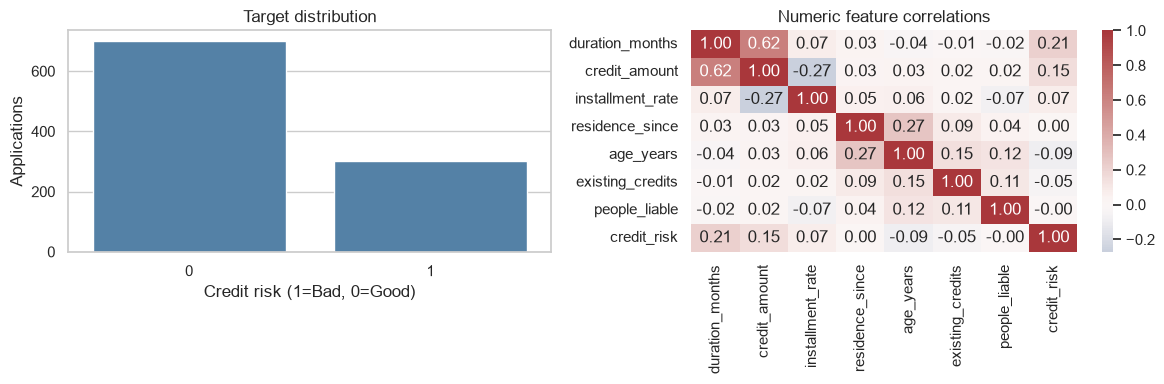

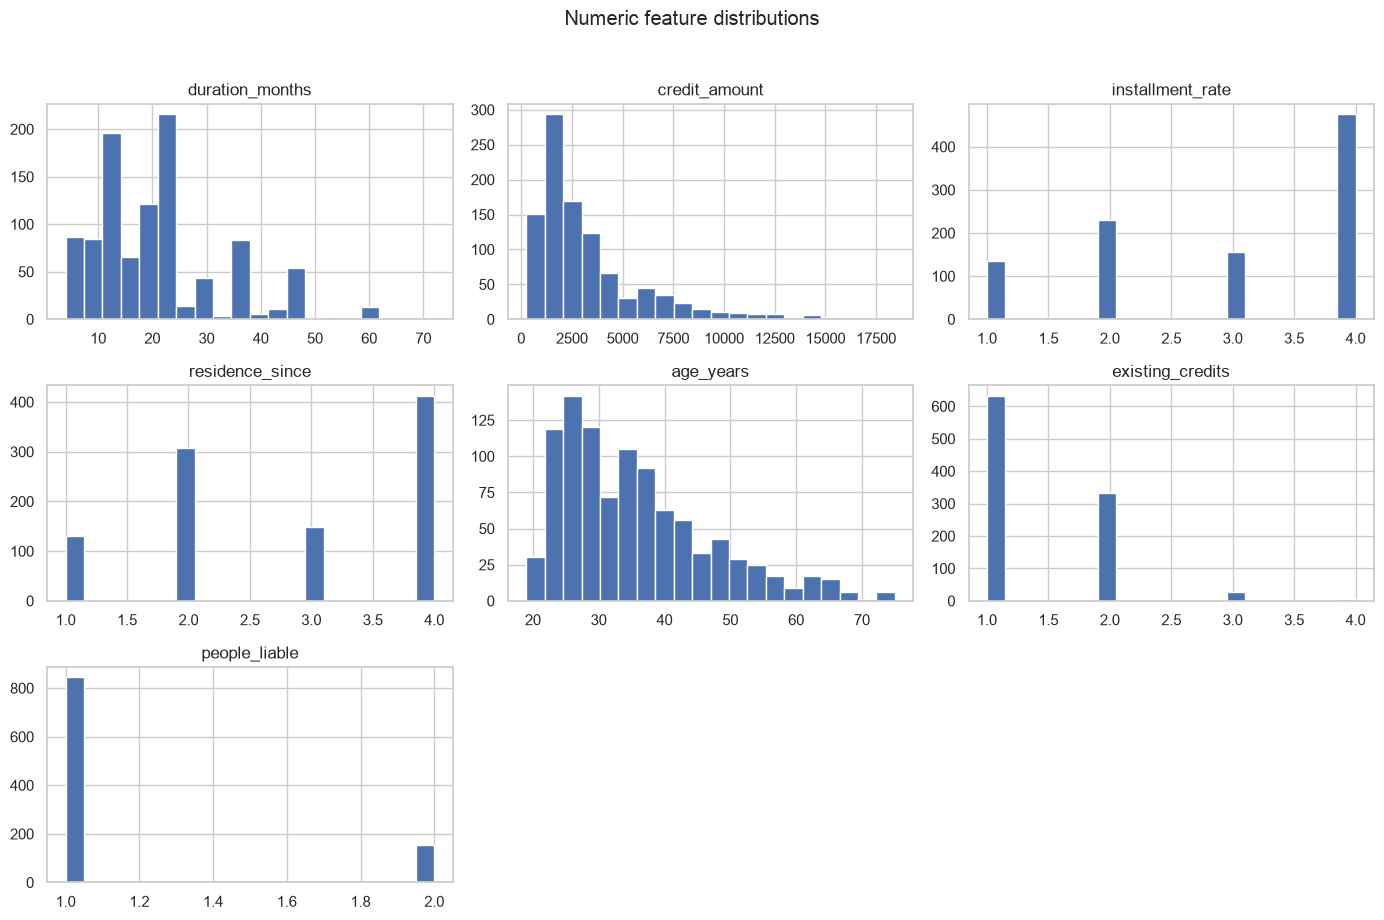

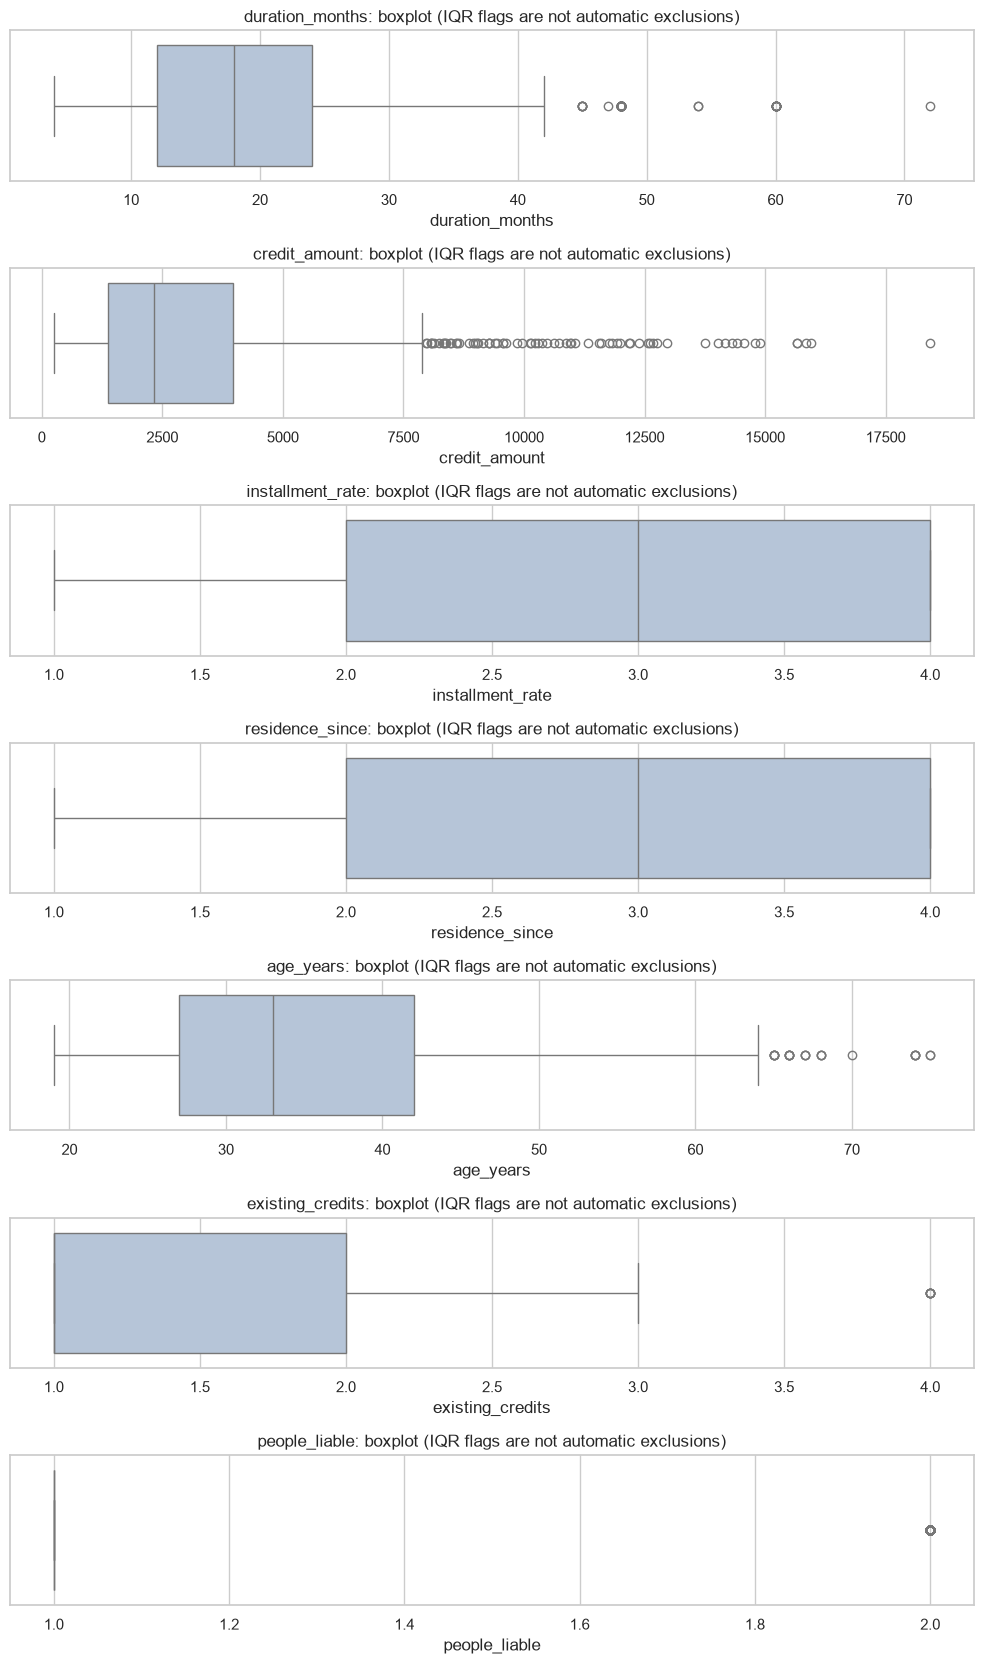

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=clean, x="credit_risk", ax=axes[0], color="steelblue")
axes[0].set(title="Target distribution", xlabel="Credit risk (1=Bad, 0=Good)", ylabel="Applications")
sns.heatmap(clean[numeric_columns + ["credit_risk"]].corr(), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Numeric feature correlations")
plt.tight_layout()
show_and_save("figure_11_1")

clean[numeric_columns].hist(bins=20, figsize=(14, 9), edgecolor="white")
plt.suptitle("Numeric feature distributions", y=1.02)
plt.tight_layout()
show_and_save("figure_11_2")

fig, axes = plt.subplots(len(numeric_columns), 1, figsize=(10, 2.4 * len(numeric_columns)))
for ax, column in zip(axes, numeric_columns):
    sns.boxplot(data=clean, x=column, ax=ax, color="lightsteelblue")
    ax.set_title(f"{column}: boxplot (IQR flags are not automatic exclusions)")
plt.tight_layout()
show_and_save("figure_11_3")

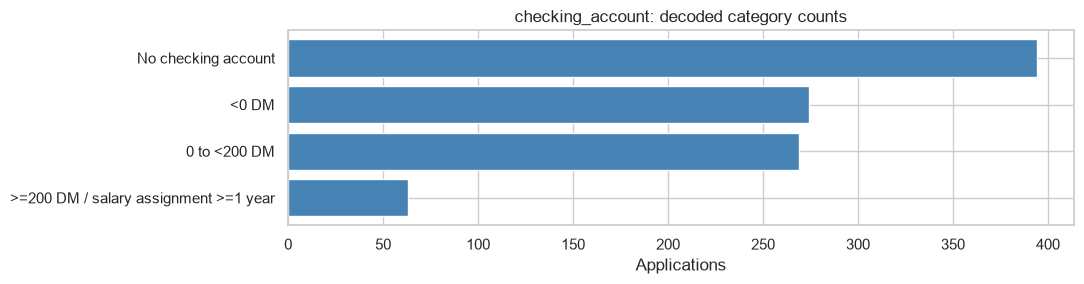

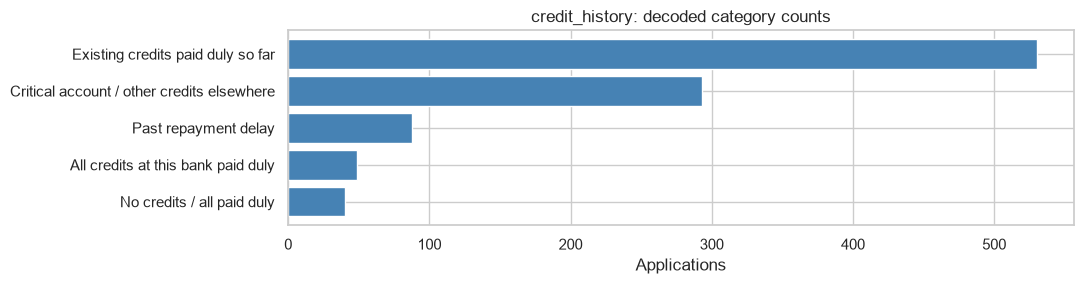

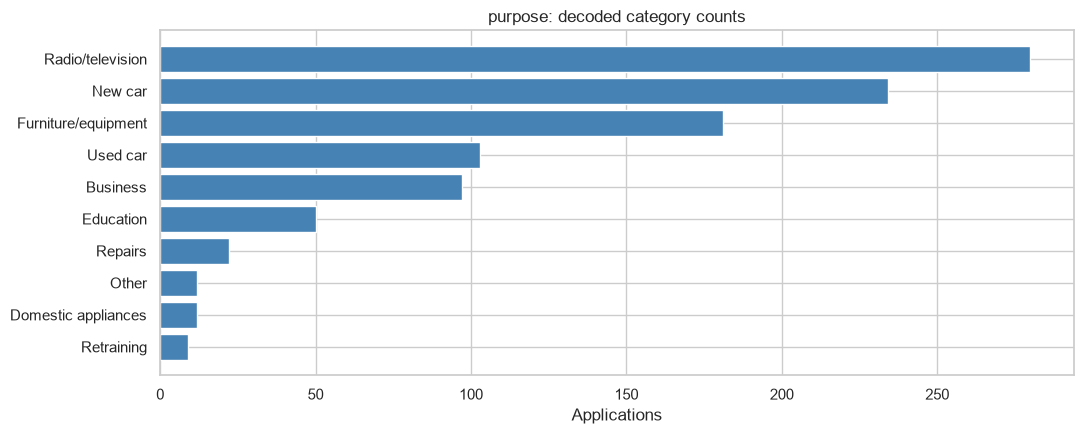

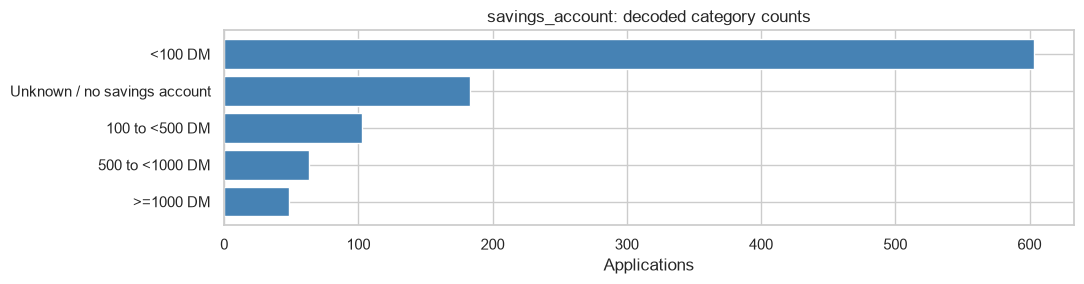

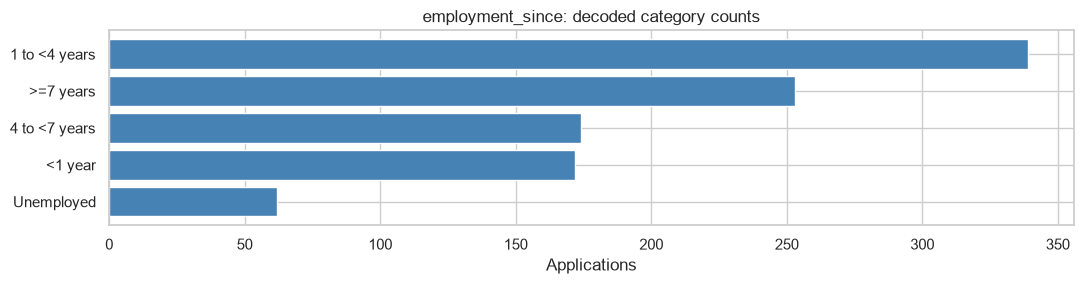

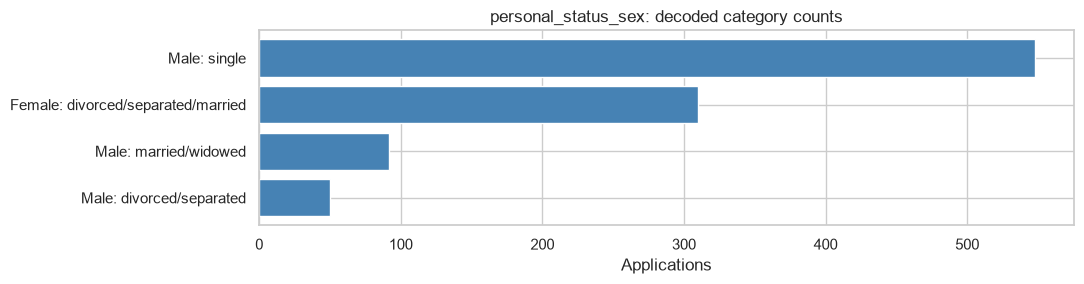

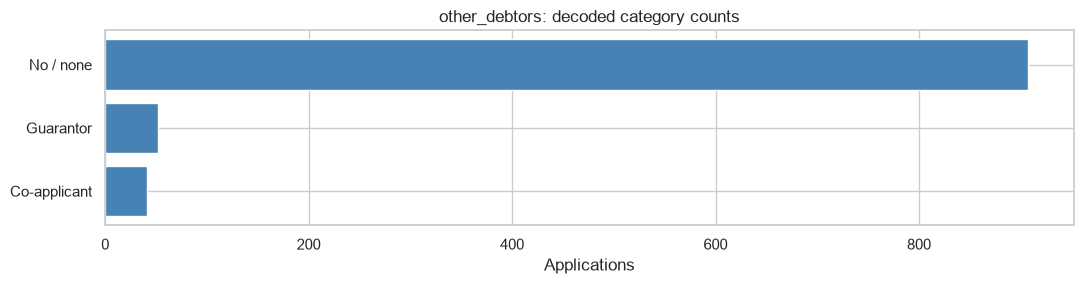

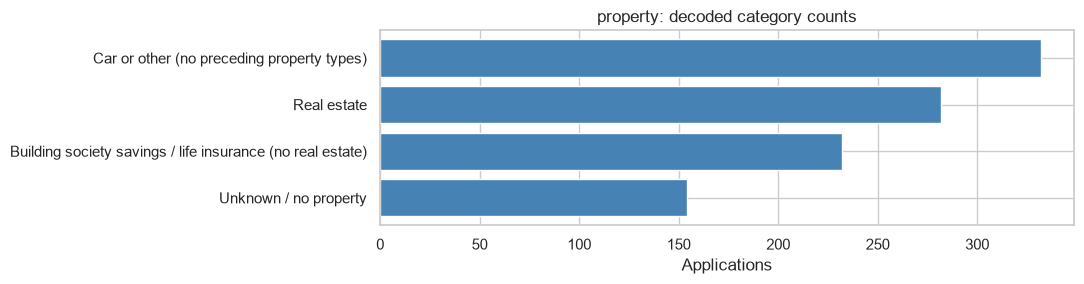

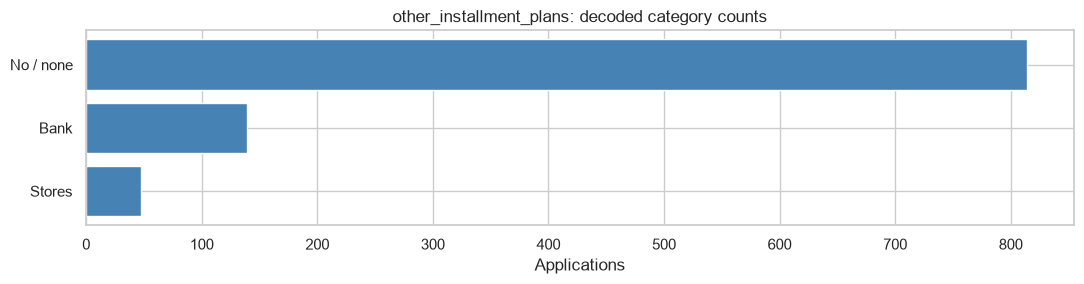

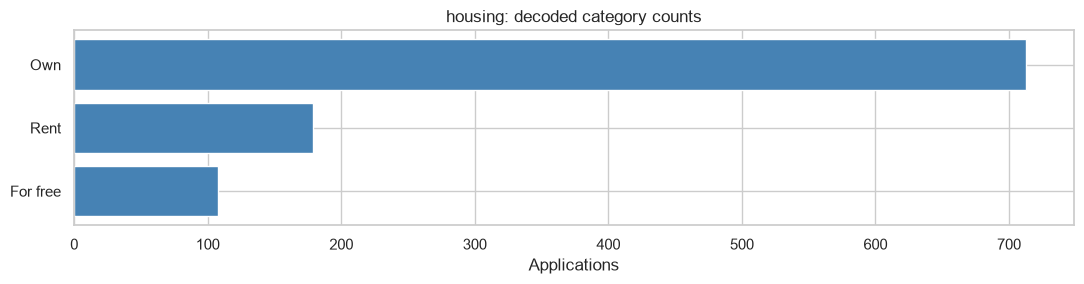

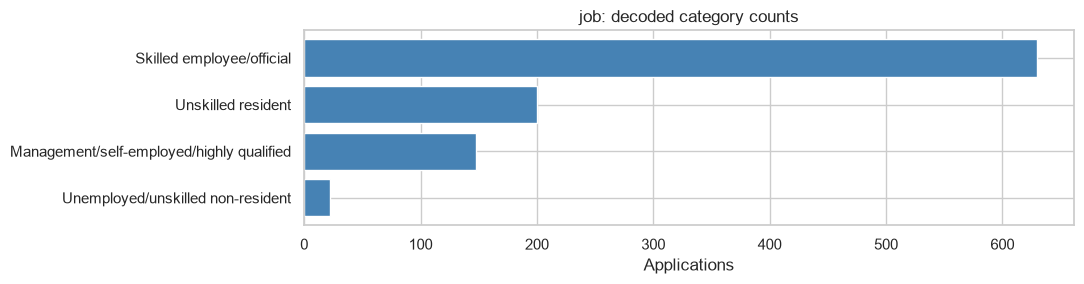

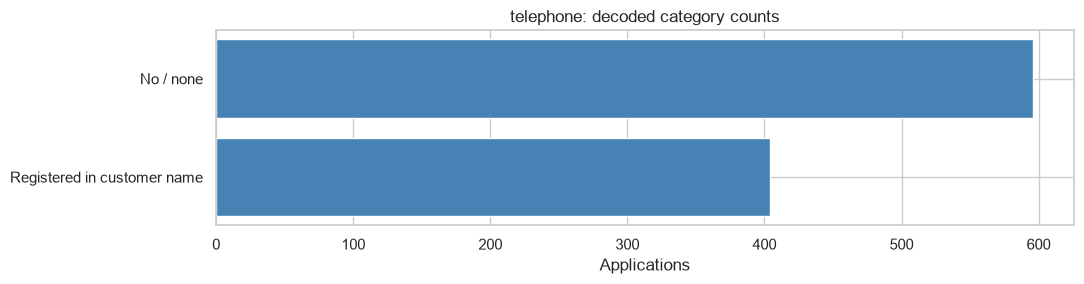

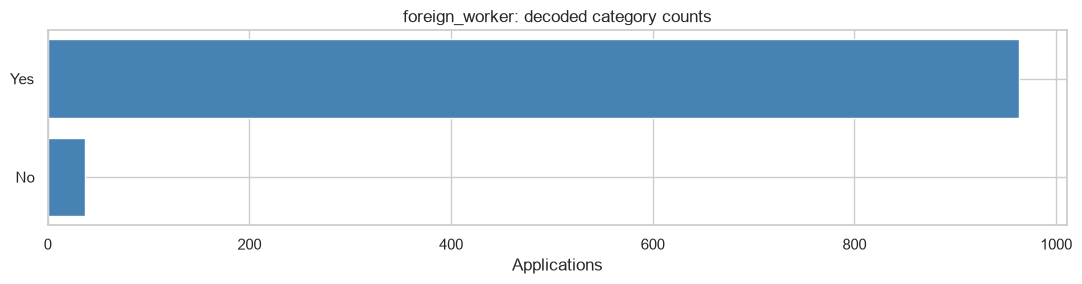

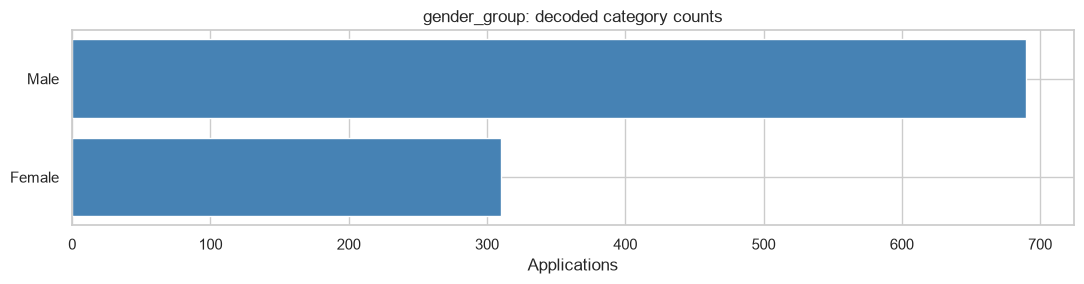

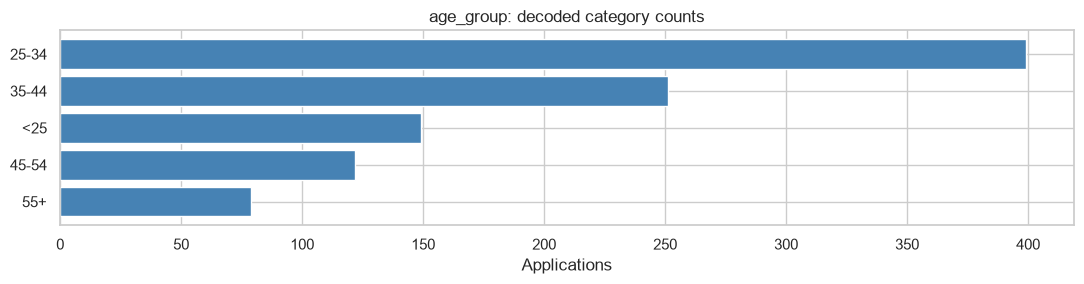

In [13]:
for column in categorical_columns + ["gender_group", "age_group"]:
    counts = clean[column].value_counts().sort_values(ascending=True)
    fig, ax = plt.subplots(figsize=(11, max(3, 0.45 * len(counts))))
    ax.barh(counts.index, counts.values, color="steelblue")
    ax.set(title=f"{column}: decoded category counts", xlabel="Applications", ylabel="")
    plt.tight_layout()
    show_and_save(f"category_{column}")


### 1.4 Fixed train/test split

Stratified 80/20 split, seed 4212. Source row IDs are preserved. The split is saved to `outputs/train.csv` and `outputs/test.csv`, and every later section uses exactly these rows.


In [14]:
train_df, test_df = train_test_split(
    clean,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=clean["original_label"].eq(1).astype(int)  # Preserve original Good=1 split ordering,
)
train_df = train_df.sort_values("original_row_index")
test_df = test_df.sort_values("original_row_index")

clean.to_csv(OUT / "cleaned_german_credit.csv", index=False)
train_df.to_csv(OUT / "train.csv", index=False)
test_df.to_csv(OUT / "test.csv", index=False)
print(f"Train: {len(train_df)} rows; test: {len(test_df)} rows; random_state={RANDOM_STATE}")
print("Train target proportions:")
display(train_df["credit_risk"].value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print("Test target proportions:")
display(test_df["credit_risk"].value_counts(normalize=True).sort_index().rename("proportion").to_frame())
print(f"Saved split files under: {OUT.resolve()}")

Train: 800 rows; test: 200 rows; random_state=4212
Train target proportions:


,proportion
credit_risk,
0,0.7
1,0.3


Test target proportions:


,proportion
credit_risk,
0,0.7
1,0.3


Saved split files under: /Users/sarah/Desktop/DSE4212-Creditscoring/outputs


## 2. Feature engineering
The raw variables each describe one aspect of a borrower. The eight engineered features below combine them to capture repayment burden and combinations of risk factors, which a linear model cannot form on its own. Every threshold is computed from the **training set only**.

The saved split is reloaded so that Sections 2–6 work on exactly the files on disk.

In [15]:
train = pd.read_csv(OUT / "train.csv")
test = pd.read_csv(OUT / "test.csv")
print("train:", train.shape, "| test:", test.shape)
train.head()

train: (800, 27) | test: (200, 27)


,original_row_index,checking_account,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate,personal_status_sex,other_debtors,residence_since,property,age_years,other_installment_plans,housing,existing_credits,job,people_liable,telephone,foreign_worker,original_label,credit_risk,gender_group,age_group,log1p_credit_amount,log1p_duration_months
0,1,0 to <200 DM,48,Existing credits paid duly so far,Radio/television,5951,<100 DM,1 to <4 years,2,Female: divorced/separated/married,No / none,2,Real estate,22,No / none,Own,1,Skilled employee/official,1,No / none,Yes,2,1,Female,<25,8.691483,3.891820
1,2,No checking account,12,Critical account / other credits elsewhere,Education,2096,<100 DM,4 to <7 years,2,Male: single,No / none,3,Real estate,49,No / none,Own,1,Unskilled resident,2,No / none,Yes,1,0,Male,45-54,7.648263,2.564949
2,3,<0 DM,42,Existing credits paid duly so far,Furniture/equipment,7882,<100 DM,4 to <7 years,2,Male: single,Guarantor,4,Building society savings / life insurance (no ...,45,No / none,For free,1,Skilled employee/official,2,No / none,Yes,1,0,Male,45-54,8.972464,3.761200
3,4,<0 DM,24,Past repayment delay,New car,4870,<100 DM,1 to <4 years,3,Male: single,No / none,4,Unknown / no property,53,No / none,For free,2,Skilled employee/official,2,No / none,Yes,2,1,Male,45-54,8.491055,3.218876
4,5,No checking account,36,Existing credits paid duly so far,Education,9055,Unknown / no savings account,1 to <4 years,2,Male: single,No / none,4,Unknown / no property,35,No / none,For free,1,Unskilled resident,2,Registered in customer name,Yes,1,0,Male,35-44,9.111183,3.610918


In [16]:
# Copy the training dataset first
train_fe = train.copy()

### 2.1 Constructing the features

#### Feature 1: Monthly Principal Repayment Proxy



In [17]:
train_fe["monthly_principal_proxy"] = (
    train_fe["credit_amount"] / train_fe["duration_months"]
)

#### Feature 2: Large Loan & Short Employment

In [18]:
credit_q75 = train["credit_amount"].quantile(0.75)

train_fe["large_loan_short_employment"] = (
    (train_fe["credit_amount"] > credit_q75) &
    (train_fe["employment_since"].isin([
        "Unemployed",
        "<1 year"
    ]))
).astype(int)

#### Feature 3: Large Loan & Low Savings

In [19]:
train_fe["large_loan_low_savings"] = (
    (train_fe["credit_amount"] > credit_q75) &
    (train_fe["savings_account"] == "<100 DM")
).astype(int)

#### Feature 4: Low Savings & Negative Checking Balance

In [20]:
train_fe["low_savings_negative_checking"] = (
    (train_fe["savings_account"] == "<100 DM") &
    (train_fe["checking_account"] == "<0 DM")
).astype(int)

#### Feature 5: Loan Amount Per Existing Credit

In [21]:
train_fe["loan_per_credit"] = (
    train_fe["credit_amount"] / train_fe["existing_credits"]
)

#### Feature 6: Has Other Installment Plan

In [22]:
train_fe["has_other_installment_plan"] = (
    train_fe["other_installment_plans"] != "No / none"
).astype(int)

#### Feature 7: Poor Credit History & Multiple Credits

In [23]:
poor_history = ["Past repayment delay", "Critical account / other credits elsewhere"]

train_fe["poor_history_multiple_credits"] = (
    (train_fe["credit_history"].isin(poor_history)) &
    (train_fe["existing_credits"] > 1)
).astype(int)

#### Feature 8: Long Duration & Large Loan

In [24]:
duration_q75 = train["duration_months"].quantile(0.75)

train_fe["long_duration_large_loan"] = (
    (train_fe["duration_months"] > duration_q75) &
    (train_fe["credit_amount"] > credit_q75)
).astype(int)

### 2.2 Inspecting the engineered features

In [25]:
engineered_features = [
    "monthly_principal_proxy",
    "large_loan_short_employment",
    "large_loan_low_savings",
    "low_savings_negative_checking",
    "loan_per_credit",
    "has_other_installment_plan",
    "poor_history_multiple_credits",
    "long_duration_large_loan"
]

display(train_fe[engineered_features].head())

,monthly_principal_proxy,large_loan_short_employment,large_loan_low_savings,low_savings_negative_checking,loan_per_credit,has_other_installment_plan,poor_history_multiple_credits,long_duration_large_loan
0,123.979167,0,1,0,5951.0,0,0,1
1,174.666667,0,0,0,2096.0,0,0,0
2,187.666667,0,1,1,7882.0,0,0,1
3,202.916667,0,1,1,2435.0,0,1,0
4,251.527778,0,0,0,9055.0,0,0,1


In [26]:
# Ensure no missing or infinite values
print("Missing values:")
display(train_fe[engineered_features].isna().sum())

print("Infinite values:")
display(
    pd.Series(
        np.isinf(train_fe[engineered_features]).sum(),
        index=engineered_features
    )
)

Missing values:


monthly_principal_proxy          0
large_loan_short_employment      0
large_loan_low_savings           0
low_savings_negative_checking    0
loan_per_credit                  0
has_other_installment_plan       0
poor_history_multiple_credits    0
long_duration_large_loan         0
dtype: int64

Infinite values:


monthly_principal_proxy          0
large_loan_short_employment      0
large_loan_low_savings           0
low_savings_negative_checking    0
loan_per_credit                  0
has_other_installment_plan       0
poor_history_multiple_credits    0
long_duration_large_loan         0
dtype: int64

#### Distributions

,monthly_principal_proxy,loan_per_credit
count,800.000000,800.000000
mean,168.976272,2647.329271
std,160.634570,2543.305805
min,25.250000,169.000000
25%,87.766667,1036.375000
50%,129.895833,1862.500000
75%,208.369792,3333.750000
max,2482.666667,18424.000000


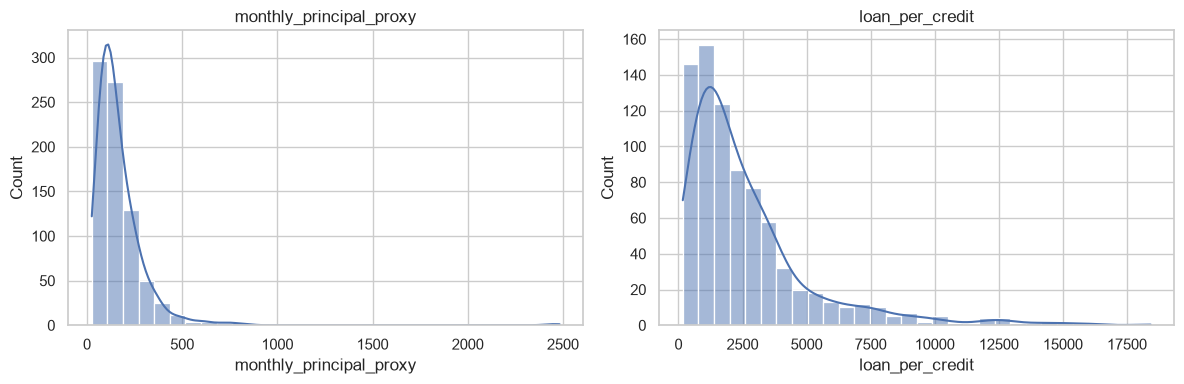

In [27]:
# Continuous Features
continuous_features = ["monthly_principal_proxy", "loan_per_credit"]

display(train_fe[continuous_features].describe())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, continuous_features):
    sns.histplot(
        data=train_fe,
        x=col,
        bins=30,
        kde=True,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

Both distributions are heavily right-skewed, with most borrowers having relatively small monthly principal repayment amounts and loans per credit.

In [28]:
# Binary Features
binary_features = [
    col for col in engineered_features
    if col not in continuous_features
]

binary_summary = pd.DataFrame({
    "Count (1)": train_fe[binary_features].sum(),
    "Percentage (1)": train_fe[binary_features].mean() * 100
})

display(binary_summary.round(2))

,Count (1),Percentage (1)
large_loan_short_employment,48,6.00
large_loan_low_savings,117,14.62
low_savings_negative_checking,180,22.50
has_other_installment_plan,151,18.88
poor_history_multiple_credits,221,27.62
long_duration_large_loan,122,15.25


All features except large_loan_short_employment occur in 15-28% of training observations.

In [29]:
summary = train_fe.groupby("large_loan_short_employment")["credit_risk"].agg(
    count="count",
    bad_credit_rate="mean"
)

display(summary.round(3))

,count,bad_credit_rate
large_loan_short_employment,,
0,752,0.290
1,48,0.458


In [30]:
pd.crosstab(
    train_fe["large_loan_short_employment"],
    train_fe["credit_risk"],
    margins=True
)

credit_risk,0,1,All
large_loan_short_employment,,,
0,534,218,752
1,26,22,48
All,560,240,800


The large_loan_short_employment feature identifies borrowers requesting loans above the 75th percentile of credit amount who are unemployed or have less than one year of employment tenure. Although only 6% of training observations satisfy this condition, their observed bad-credit rate is 45.8%, compared with 29.0% for other borrowers. This suggests a potential association between the interaction and credit risk, motivating its inclusion as a candidate predictor. 

### 2.3 Skew fixes

In [31]:
train_fe["log_monthly_principal_proxy"] = np.log1p(
    train_fe["monthly_principal_proxy"]
)

train_fe["log_loan_per_credit"] = np.log1p(
    train_fe["loan_per_credit"]
)

skew_comparison = pd.DataFrame({
    "Original": train_fe[
        ["monthly_principal_proxy", "loan_per_credit"]
    ].skew().values,
    "Log-transformed": train_fe[
        ["log_monthly_principal_proxy", "log_loan_per_credit"]
    ].skew().values
}, index=["monthly_principal_proxy", "loan_per_credit"])

display(skew_comparison)

,Original,Log-transformed
monthly_principal_proxy,7.932746,0.444044
loan_per_credit,2.405388,0.030845


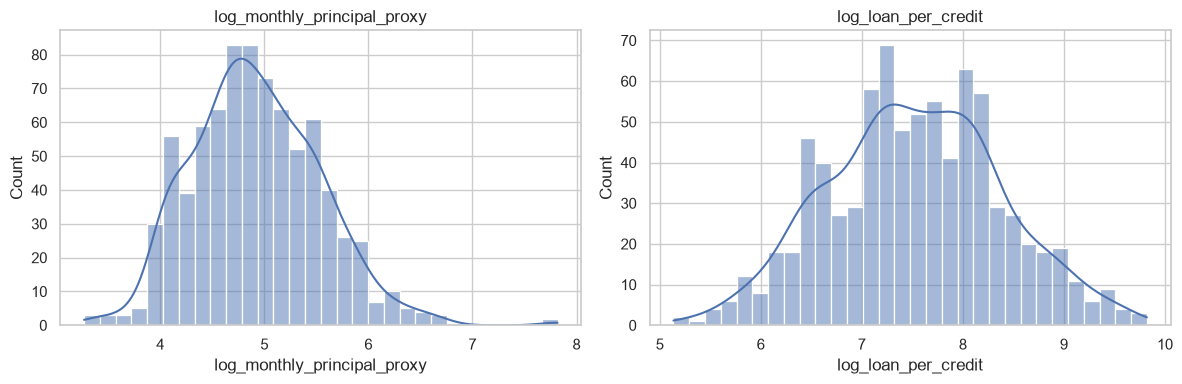

In [32]:
log_features = ["log_monthly_principal_proxy", "log_loan_per_credit"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col in zip(axes, log_features):
    sns.histplot(
        data=train_fe,
        x=col,
        bins=30,
        kde=True,
        ax=ax
    )
    ax.set_title(col)

plt.tight_layout()
plt.show()

Applying a log(1+x) transformation reduced the skewness of monthly principal proxy and loan per existing credit.

### 2.4 Encoding check
A manual version of the encoding, to inspect the final model matrix. Section 2.5 packages the same steps into a reusable pipeline.

In [33]:
# Numerical features
numeric_features = [
    "existing_credits",
    "people_liable",
    "log_monthly_principal_proxy",
    "log_loan_per_credit",
    "log1p_credit_amount",
    "log1p_duration_months"
]

# Categorical features
categorical_features = [
    "checking_account",
    "credit_history",
    "purpose",
    "savings_account",
    "employment_since",
    "other_debtors",
    "property",
    "other_installment_plans",
    "housing",
    "job",
    "telephone",
    "foreign_worker",
    "installment_rate",
    "residence_since"
]

# Binary engineered features
binary_features = [
    "large_loan_short_employment",
    "large_loan_low_savings",
    "low_savings_negative_checking",
    "has_other_installment_plan",
    "poor_history_multiple_credits",
    "long_duration_large_loan"
]

all_features = numeric_features + categorical_features + binary_features

X_fe = train_fe[all_features]

print("Number of input features:", len(all_features))
print("Training shape:", X_fe.shape)

Number of input features: 26
Training shape: (800, 26)


In [34]:
# Numerical preprocessing
numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine transformations
preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
    ("binary", "passthrough", binary_features)
])

In [35]:
# Transform data
X_train_processed = preprocessor.fit_transform(X_fe)

print("Original shape:", X_fe.shape)
print("Processed shape:", X_train_processed.shape)

Original shape: (800, 26)
Processed shape: (800, 70)


#### Inspect the encoded dataset

In [36]:
# Get feature names
encoded_names = preprocessor.get_feature_names_out()

print("Number of processed features:", len(encoded_names))

display(pd.DataFrame({
    "feature_name": encoded_names
}))

Number of processed features: 70


,feature_name
0,num__existing_credits
1,num__people_liable
2,num__log_monthly_principal_proxy
3,num__log_loan_per_credit
4,num__log1p_credit_amount
...,...
65,binary__large_loan_low_savings
66,binary__low_savings_negative_checking
67,binary__has_other_installment_plan
68,binary__poor_history_multiple_credits


In [37]:
X_train_processed_df = pd.DataFrame(
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed,
    columns=encoded_names,
    index=X_fe.index
)

display(X_train_processed_df.head())

,num__existing_credits,num__people_liable,num__log_monthly_principal_proxy,num__log_loan_per_credit,num__log1p_credit_amount,num__log1p_duration_months,cat__checking_account_0 to <200 DM,cat__checking_account_<0 DM,cat__checking_account_>=200 DM / salary assignment >=1 year,cat__checking_account_No checking account,cat__credit_history_All credits at this bank paid duly,cat__credit_history_Critical account / other credits elsewhere,cat__credit_history_Existing credits paid duly so far,cat__credit_history_No credits / all paid duly,cat__credit_history_Past repayment delay,...,cat__foreign_worker_Yes,cat__installment_rate_1,cat__installment_rate_2,cat__installment_rate_3,cat__installment_rate_4,cat__residence_since_1,cat__residence_since_2,cat__residence_since_3,cat__residence_since_4,binary__large_loan_short_employment,binary__large_loan_low_savings,binary__low_savings_negative_checking,binary__has_other_installment_plan,binary__poor_history_multiple_credits,binary__long_duration_large_loan
0,-0.712917,-0.434405,-0.154850,1.370626,1.152417,1.717077,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,-0.712917,2.302002,0.400080,0.149435,-0.180267,-0.673560,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,-0.712917,2.302002,0.516454,1.699542,1.511363,1.481737,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,1.0
3,1.052821,2.302002,0.643156,0.324848,0.896376,0.504626,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,1.0,0.0,1.0,0.0
4,-0.712917,2.302002,0.991673,1.861926,1.688572,1.210972,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [38]:
print("Missing values:",
      X_train_processed_df.isna().sum().sum())

print("Infinite values:",
      np.isinf(X_train_processed_df.to_numpy()).sum())

print("Processed shape:",
      X_train_processed_df.shape)

display(
    X_train_processed_df[
        [col for col in encoded_names if col.startswith("num__")]
    ].describe().round(3)
)

Missing values: 0
Infinite values: 0
Processed shape: (800, 70)


,num__existing_credits,num__people_liable,num__log_monthly_principal_proxy,num__log_loan_per_credit,num__log1p_credit_amount,num__log1p_duration_months
count,800.000,800.000,800.000,800.000,800.000,800.000
mean,-0.000,0.000,-0.000,-0.000,-0.000,0.000
std,1.001,1.001,1.001,1.001,1.001,1.001
min,-0.713,-0.434,-2.698,-2.792,-2.766,-2.395
25%,-0.713,-0.434,-0.713,-0.674,-0.729,-0.674
50%,-0.713,-0.434,-0.079,0.011,-0.062,0.010
75%,1.053,-0.434,0.686,0.692,0.637,0.505
max,4.584,2.302,4.718,2.693,2.596,2.435


### 2.5 Shared pipeline (Section 0.1)
The steps above are packaged as a scikit-learn pipeline: `FeatureEngineer` (the eight features and log transforms, with the 75th-percentile cut-offs learned in `fit`), then `make_preprocessor` (imputation, one-hot encoding, optional scaling). Because the whole pipeline is refitted inside every cross-validation fold, no information from validation or test rows leaks into the features. The cells below check that the packaged version reproduces the manual one.

In [39]:
# The packaged FeatureEngineer must reproduce the manually built columns exactly
fe_check = FeatureEngineer().fit(train).transform(train)
for col in engineered_features + ["log_monthly_principal_proxy", "log_loan_per_credit"]:
    assert np.allclose(fe_check[col], train_fe[col]), col
print("FeatureEngineer reproduces all 10 engineered columns built above.")

FeatureEngineer reproduces all 10 engineered columns built above.


In [40]:
X_check = train.drop(columns=["credit_risk", "original_label"])

pipeline_check = make_pipeline(
    LogisticRegression(max_iter=1000, random_state=4212),
    scale_numeric=True
)

pipeline_check.fit(X_check, train["credit_risk"])

print("Pipeline fitted successfully!")
print("Classes:", pipeline_check.classes_)

Pipeline fitted successfully!
Classes: [0 1]


In [41]:
pipeline_names = pipeline_check.named_steps["preprocessing"].get_feature_names_out()

print("Number of processed features:", len(pipeline_names))

display(pd.DataFrame({
    "feature": pipeline_names
}))

Number of processed features: 70


,feature
0,num__existing_credits
1,num__people_liable
2,num__log1p_credit_amount
3,num__log1p_duration_months
4,num__log_monthly_principal_proxy
...,...
65,binary__large_loan_low_savings
66,binary__low_savings_negative_checking
67,binary__has_other_installment_plan
68,binary__poor_history_multiple_credits


## 3. Modelling
All three models are trained and tested on exactly the same rows, using the shared pipeline from Section 2.5.

In [42]:
# Model figures use plain matplotlib styling
plt.style.use("default")
matplotlib.rcParams.update({"font.size": 12})

y_train, y_test = train[TARGET].astype(int), test[TARGET].astype(int)
X_train, X_test = train.drop(columns=[TARGET]), test.drop(columns=[TARGET])

print("train:", X_train.shape, "| test:", X_test.shape)
print(f"Default rate: train {y_train.mean():.3f}, test {y_test.mean():.3f}")
check_inputs(X_train)   # raises if expected columns are missing

train: (800, 26) | test: (200, 26)
Default rate: train 0.300, test 0.300


### 3.1 Shared methodology
**Preprocessing.** Every model uses the shared `make_pipeline` (Sections 0.1 and 2.5): the 8
engineered features, one-hot encoding of categoricals and median/mode imputation. Numeric features are
standardised for logistic regression (`scale_numeric=True`) but not for the tree models, because
monotone rescaling does not change a tree split. Sensitive attributes (`gender_group`, `age_group`)
are never model inputs.

**Cross-validation.** Hyperparameters are tuned with `RepeatedStratifiedKFold` (5 folds × 2 repeats,
seed 4212) on the training set only, scored on ROC AUC. Each fold keeps the 70/30 class ratio and has
about 190 defaults, enough for a stable AUC. The repeat reduces the noise from a single split. ROC AUC
does not depend on a threshold and is not distorted by class imbalance. Train-fold AUC is also
recorded to check for overfitting.

**Class imbalance (30% defaults)** is handled at two levels:
1. *Training:* class reweighting (`class_weight`) is included in the tree models' grids and kept
   only if CV prefers it.
2. *Decision:* the classification threshold is set from **out-of-fold training predictions**, never
   from the test set. Three operating points are reported:
   - 0.5, the default
   - the F1-optimal threshold
   - the cost-optimal threshold, minimising `FN_COST`·FN + FP

**Evaluation.** Every model is scored once on the test set with the shared `evaluate()` function.

The helpers below implement these steps once, for all three models.

In [43]:
CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=RANDOM_STATE)   # tuning
OOF_CV = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)               # thresholds


def tune(pipeline, param_grid, name):
    """Grid search on the training set (ROC AUC, repeated stratified CV). Returns (search, results)."""
    gs = GridSearchCV(pipeline, param_grid, scoring="roc_auc", cv=CV, n_jobs=-1,
                      refit=True, return_train_score=True)
    t0 = time.time()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gs.fit(X_train, y_train)
    cvr = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score").reset_index(drop=True)
    print(f"{name}: {len(cvr)} settings x {CV.get_n_splits()} fits in {time.time() - t0:.0f}s")
    print(f"Best params: { {k.replace('classifier__', ''): v for k, v in gs.best_params_.items()} }")
    print(f"CV AUC {gs.best_score_:.4f} (+/- {cvr.loc[0, 'std_test_score']:.4f}) | "
          f"mean train-fold AUC {cvr.loc[0, 'mean_train_score']:.4f}")
    cols = [c for c in cvr if c.startswith("param_")] + ["mean_test_score", "std_test_score",
                                                         "mean_train_score"]
    display(cvr[cols].head(8).rename(columns=lambda c: c.replace("param_classifier__", "")))
    return gs, cvr


def operating_points(model, prefix, label):
    """Thresholds from out-of-fold training predictions, then a single test-set evaluation."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        oof = cross_val_predict(model, X_train, y_train, method="predict_proba", cv=OOF_CV)[:, 1]
    pd.DataFrame({"index": X_train.index, "y_true": y_train.values, "y_proba": oof}).to_csv(
        OUT / f"predictions/{prefix}_train_oof_proba.csv", index=False)

    t_f1 = f1_optimal_threshold(y_train, oof)
    t_cost = cost_min_threshold(y_train, oof, cost_fn=FN_COST)
    print(f"[{label}] F1-optimal threshold {t_f1:.3f} | cost-optimal threshold {t_cost:.3f}\n")

    op = {"oof": oof, "t_f1": t_f1, "t_cost": t_cost}
    op["res_05"] = evaluate(model, X_test, y_test, threshold=0.5, name=f"{label} tuned @ 0.5",
                            fn_cost=FN_COST, save_to=str(OUT / f"predictions/{prefix}_test_proba.csv"))
    op["res_f1"] = evaluate(model, X_test, y_test, threshold=t_f1,
                            name=f"{label} tuned @ F1-optimal", fn_cost=FN_COST)
    op["res_cost"] = evaluate(model, X_test, y_test, threshold=t_cost,
                              name=f"{label} tuned @ cost-optimal", fn_cost=FN_COST)
    op["ci"] = bootstrap_auc_ci(y_test, op["res_05"]["y_proba"])
    print(f"\nTest AUC = {op['res_05']['auc']:.3f}, 95% bootstrap CI "
          f"[{op['ci'][0]:.3f}, {op['ci'][1]:.3f}]")
    return op


def plot_operating_points(op, roc_models, title, fname):
    """ROC (test), out-of-fold probability histogram with thresholds, confusion matrix at cost-opt."""
    fig, axes = plt.subplots(1, 3, figsize=(17, 5))
    for res, lab in roc_models:
        fpr, tpr, _ = roc_curve(y_test, res["y_proba"])
        axes[0].plot(fpr, tpr, label=f"{lab} (AUC = {res['auc']:.3f})")
    axes[0].plot([0, 1], [0, 1], "--", color="gray")
    axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title=f"{title}: ROC - test set")
    axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

    bins = np.linspace(0, 1, 41)
    axes[1].hist(op["oof"][y_train == 0], bins=bins, alpha=0.6, label="good")
    axes[1].hist(op["oof"][y_train == 1], bins=bins, alpha=0.6, label="default")
    for t, ls, lab in [(0.5, ":", "0.5"), (op["t_f1"], "--", "F1-opt"), (op["t_cost"], "-", "cost-opt")]:
        axes[1].axvline(t, color="k", ls=ls, lw=1, label=f"{lab} = {t:.2f}")
    axes[1].set(xlabel="Predicted P(default)", ylabel="Count", title="Out-of-fold probabilities (train)")
    axes[1].legend()

    ConfusionMatrixDisplay(op["res_cost"]["confusion_matrix"], display_labels=["good", "default"]).plot(
        ax=axes[2], colorbar=False, cmap="Blues")
    axes[2].set_title(f"Confusion matrix (threshold {op['t_cost']:.3f})")
    plt.tight_layout()
    plt.savefig(OUT / f"results/{fname}", dpi=200)
    plt.show()

### 3.2 Logistic regression
#### Naive baseline (Chapter 6 approach)
A plain `LogisticRegression()` on 7 numeric columns only, with no scaling, no categorical variables and
no tuning, as fitted in class. It is repeated here on the shared split so it is directly comparable.

In [44]:
naive_features = ["log1p_credit_amount", "log1p_duration_months", "installment_rate",
                  "residence_since", "age_years", "existing_credits", "people_liable"]

naive = LogisticRegression(max_iter=1000)
naive.fit(X_train[naive_features], y_train)
res_naive = evaluate(naive, X_test[naive_features], y_test,
                     name="Naive LR (7 numeric features)", fn_cost=FN_COST, report=True)

=== Naive LR (7 numeric features) | threshold = 0.500 ===
AUC 0.6799 | Precision 0.8333 | Recall 0.0833 | F1 0.1515 | Accuracy 0.7200
          pred 0  pred 1
actual 0     139       1
actual 1      55       5
              precision    recall  f1-score   support

           0       0.72      0.99      0.83       140
           1       0.83      0.08      0.15        60

    accuracy                           0.72       200
   macro avg       0.77      0.54      0.49       200
weighted avg       0.75      0.72      0.63       200



**Remark.** Accuracy looks acceptable only because 70% of clients are good: predicting
"good" for everyone already scores 0.70. The recall on defaults and the AUC are the
informative numbers, and both are weak.

#### Untuned reference (shared pipeline)
The untuned `LogisticRegression(max_iter=1000)` (C = 1, L2 penalty) on the full shared pipeline.

In [45]:
lr_default = make_pipeline(LogisticRegression(max_iter=1000), scale_numeric=True)
lr_default.fit(X_train, y_train)
res_lr_default = evaluate(lr_default, X_test, y_test, name="LR untuned (C=1, L2)", fn_cost=FN_COST)

=== LR untuned (C=1, L2) | threshold = 0.500 ===
AUC 0.8150 | Precision 0.6809 | Recall 0.5333 | F1 0.5981 | Accuracy 0.7850
          pred 0  pred 1
actual 0     125      15
actual 1      28      32


#### Tuning
Grid: `C` (inverse regularisation strength, 11 log-spaced values from 0.001 to 100) × `l1_ratio`
(0 = ridge, 0.5 = elastic net, 1 = lasso), with the SAGA solver. `penalty="elasticnet"` is set
explicitly so that `l1_ratio` takes effect in every scikit-learn version. With `l1_ratio = 0` this
is the ordinary L2 (ridge) model. Class imbalance is handled by the threshold (Section 4.1).

In [46]:
lr_base = make_pipeline(
    LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.0, max_iter=20000,
                       random_state=RANDOM_STATE),
    scale_numeric=True,
)
lr_grid = {
    "classifier__C": np.logspace(-3, 2, 11),
    "classifier__l1_ratio": [0.0, 0.5, 1.0],
}
gs_lr, cvr_lr = tune(lr_base, lr_grid, "Logistic regression")
lr_best = gs_lr.best_estimator_

Logistic regression: 33 settings x 10 fits in 15s
Best params: {'C': np.float64(0.03162277660168379), 'l1_ratio': 0.0}
CV AUC 0.7692 (+/- 0.0338) | mean train-fold AUC 0.8178


,C,l1_ratio,mean_test_score,std_test_score,mean_train_score
0,0.031623,0.0,0.769178,0.033816,0.817784
1,0.100000,0.0,0.768341,0.029836,0.829146
2,0.316228,0.5,0.765551,0.027610,0.830664
3,0.316228,0.0,0.763839,0.026690,0.836085
4,0.010000,0.0,0.761403,0.037001,0.801338
5,0.316228,1.0,0.760063,0.029626,0.821702
6,1.000000,1.0,0.758966,0.024447,0.836611
7,1.000000,0.5,0.758854,0.025057,0.838224


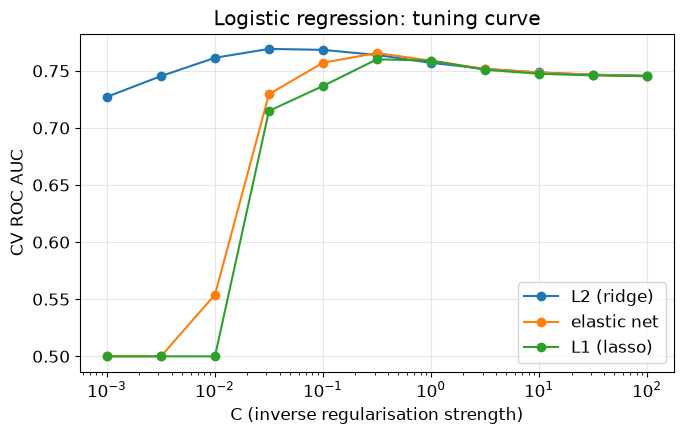

In [47]:
fig, ax = plt.subplots(figsize=(7, 4.5))
names = {0.0: "L2 (ridge)", 0.5: "elastic net", 1.0: "L1 (lasso)"}
for l1, g in cvr_lr.groupby("param_classifier__l1_ratio"):
    g = g.sort_values("param_classifier__C")
    ax.plot(g["param_classifier__C"].astype(float), g["mean_test_score"], marker="o", label=names[float(l1)])
ax.set_xscale("log")
ax.set(xlabel="C (inverse regularisation strength)", ylabel="CV ROC AUC",
       title="Logistic regression: tuning curve")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(OUT / "results/logreg_tuning_curve.png", dpi=200)
plt.show()

**Remark.** Strong regularisation (small C) with lasso or elastic net shrinks every coefficient
to zero and the AUC collapses to 0.5. Ridge is the most stable choice. The AUC is flat for moderate to
large C, so tuning gives only a small gain over the untuned model.

### 3.3 Random forest
#### Method and untuned reference
An average of many deep decision trees. Each tree is grown on a bootstrap sample of the rows and
chooses each split from a random subset of the features. Averaging de-correlated trees reduces
variance, and the trees capture non-linear effects and interactions (e.g. large loan *and* no
savings) without having to specify them.

The reference is scikit-learn's default forest: 500 fully grown trees with no class weighting.

In [48]:
rf_default = make_pipeline(RandomForestClassifier(n_estimators=500, n_jobs=-1, random_state=RANDOM_STATE),
                           scale_numeric=False)
rf_default.fit(X_train, y_train)
res_rf_default = evaluate(rf_default, X_test, y_test, name="RF untuned (500 trees)", fn_cost=FN_COST)

=== RF untuned (500 trees) | threshold = 0.500 ===
AUC 0.8082 | Precision 0.7436 | Recall 0.4833 | F1 0.5859 | Accuracy 0.7950
          pred 0  pred 1
actual 0     130      10
actual 1      31      29


#### Tuning
The number of trees is fixed at 500: more trees never hurt a forest, they only reduce the noise.
The grid controls the complexity of each tree and the randomness between trees.

| Parameter | Values | Role |
|---|---|---|
| `max_depth` | 4, 6, 8, 12, None | tree depth (None = grow fully) |
| `min_samples_leaf` | 1, 3, 5, 10 | smallest allowed leaf; larger = smoother probabilities |
| `max_features` | sqrt, 0.33 | share of features tried at each split |
| `class_weight` | None, balanced_subsample | class-imbalance reweighting inside each bootstrap sample |

80 combinations × 10 fits = 800 forests.

In [49]:
rf_base = make_pipeline(RandomForestClassifier(n_estimators=500, n_jobs=1, random_state=RANDOM_STATE),
                        scale_numeric=False)
rf_grid = {
    "classifier__max_depth": [4, 6, 8, 12, None],
    "classifier__min_samples_leaf": [1, 3, 5, 10],
    "classifier__max_features": ["sqrt", 0.33],
    "classifier__class_weight": [None, "balanced_subsample"],
}
gs_rf, cvr_rf = tune(rf_base, rf_grid, "Random forest")
rf_best = gs_rf.best_estimator_

Random forest: 80 settings x 10 fits in 83s
Best params: {'class_weight': 'balanced_subsample', 'max_depth': 8, 'max_features': 'sqrt', 'min_samples_leaf': 1}
CV AUC 0.7888 (+/- 0.0374) | mean train-fold AUC 0.9909


,class_weight,max_depth,max_features,min_samples_leaf,mean_test_score,std_test_score,mean_train_score
0,balanced_subsample,8,sqrt,1,0.788839,0.037353,0.990939
1,NaN,8,sqrt,1,0.788542,0.035113,0.989655
2,balanced_subsample,12,sqrt,1,0.788337,0.036960,0.999997
3,NaN,12,sqrt,1,0.785584,0.034214,0.999997
4,balanced_subsample,None,sqrt,1,0.785472,0.038981,1.000000
5,balanced_subsample,8,sqrt,3,0.785156,0.037221,0.970716
6,NaN,6,sqrt,3,0.784542,0.034022,0.929800
7,balanced_subsample,12,sqrt,3,0.784431,0.037290,0.990083


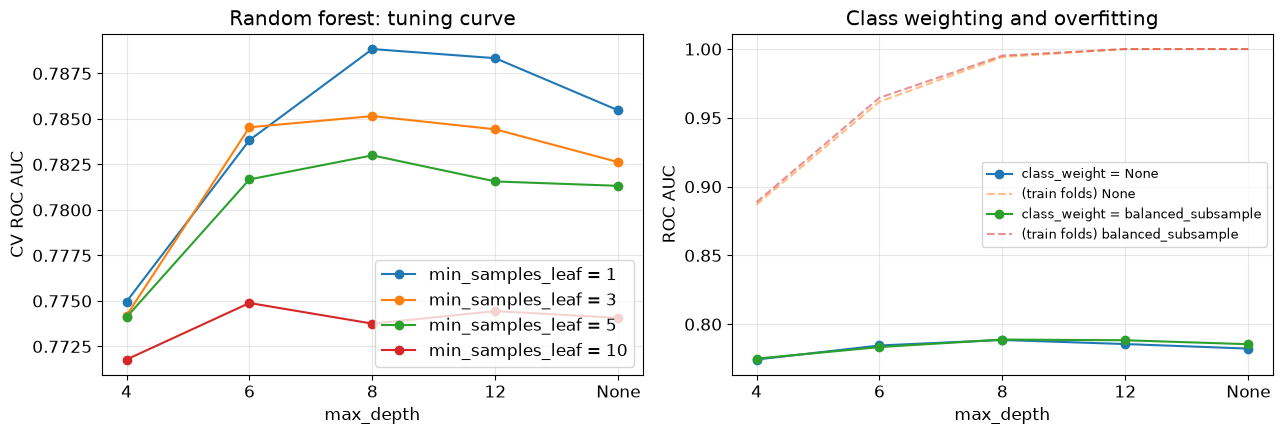

,best CV AUC,mean CV AUC over grid
weight,,
None,0.788542,0.775127
balanced_subsample,0.788839,0.777404


In [50]:
cvr_rf["depth"] = cvr_rf["param_classifier__max_depth"].apply(
    lambda d: "None" if d is None or pd.isna(d) else str(int(d)))
cvr_rf["weight"] = cvr_rf["param_classifier__class_weight"].apply(
    lambda w: "balanced_subsample" if w == "balanced_subsample" else "None")
depth_order = ["4", "6", "8", "12", "None"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for leaf, g in cvr_rf.groupby("param_classifier__min_samples_leaf"):
    s = g.groupby("depth")["mean_test_score"].max().reindex(depth_order)
    axes[0].plot(depth_order, s.values, marker="o", label=f"min_samples_leaf = {leaf}")
axes[0].set(xlabel="max_depth", ylabel="CV ROC AUC", title="Random forest: tuning curve")
axes[0].grid(alpha=0.3); axes[0].legend()

for w, g in cvr_rf.groupby("weight"):
    s = g.groupby("depth")["mean_test_score"].max().reindex(depth_order)
    axes[1].plot(depth_order, s.values, marker="o", label=f"class_weight = {w}")
    s_tr = g.groupby("depth")["mean_train_score"].max().reindex(depth_order)
    axes[1].plot(depth_order, s_tr.values, ls="--", alpha=0.5, label=f"(train folds) {w}")
axes[1].set(xlabel="max_depth", ylabel="ROC AUC", title="Class weighting and overfitting")
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "results/rf_tuning_curve.png", dpi=200)
plt.show()

cvr_rf.groupby("weight")["mean_test_score"].agg(["max", "mean"]).rename(
    columns={"max": "best CV AUC", "mean": "mean CV AUC over grid"})

**Remark.** The best forest uses trees of depth 8, leaves of 1 row, √p features per split and
`balanced_subsample` weighting (CV AUC 0.789 ± 0.037). The tuning surface is flat. The top 10 settings are
within 0.005 AUC of each other, well inside one CV standard deviation, so the exact choice matters little.
Very shallow trees (depth 4) and large leaves (10) underfit. Train-fold AUC is ≈ 0.99, so each forest almost memorises its
training rows. This is normal for random forests, and CV AUC is the honest measure.

**Class weighting barely changes the AUC** (best 0.7888 weighted vs 0.7885 unweighted). This is expected.
Reweighting shifts the predicted probabilities upwards but hardly changes how borrowers are *ranked*.
Its practical effect is on the probability scale, which the threshold in Section 4.1 handles in either case.

### 3.4 AdaBoost
#### Method and untuned reference
**AdaBoost (SAMME)** fits a *sequence* of small trees. After each round, the rows the ensemble
misclassifies get more weight, so the next tree focuses on them. The final score is a weighted vote
of all trees. Where a random forest averages deep trees to reduce variance, boosting adds shallow
trees to reduce bias. The learning rate shrinks each tree's vote and trades off against the number
of rounds.

AdaBoost's `predict_proba` is a softmax of the weighted vote. These probabilities are **squeezed
towards 0.5** and not calibrated, so learning the threshold from data (Section 4.1) matters even more
than for the other models.

The reference is scikit-learn's default: 50 decision stumps (depth 1) with learning rate 1.

In [51]:
ada_default = make_pipeline(AdaBoostClassifier(random_state=RANDOM_STATE), scale_numeric=False)
ada_default.fit(X_train, y_train)
res_ada_default = evaluate(ada_default, X_test, y_test, name="AdaBoost untuned (50 stumps, lr=1)",
                           fn_cost=FN_COST)

=== AdaBoost untuned (50 stumps, lr=1) | threshold = 0.500 ===
AUC 0.8042 | Precision 0.6818 | Recall 0.5000 | F1 0.5769 | Accuracy 0.7800
          pred 0  pred 1
actual 0     126      14
actual 1      30      30


#### Tuning
| Parameter | Values | Role |
|---|---|---|
| `n_estimators` | 100, 300, 600 | boosting rounds |
| `learning_rate` | 0.03, 0.1, 0.3, 1.0 | shrinkage of each tree's vote |
| `estimator__max_depth` | 1, 2, 3 | base-tree depth (1 = stumps, additive model; 2–3 = interactions) |
| `estimator__class_weight` | None, balanced | class-imbalance reweighting in every boosting round |

72 combinations × 10 fits = 720 ensembles.

In [52]:
ada_base = make_pipeline(
    AdaBoostClassifier(estimator=DecisionTreeClassifier(random_state=RANDOM_STATE),
                       random_state=RANDOM_STATE),
    scale_numeric=False,
)
ada_grid = {
    "classifier__n_estimators": [100, 300, 600],
    "classifier__learning_rate": [0.03, 0.1, 0.3, 1.0],
    "classifier__estimator__max_depth": [1, 2, 3],
    "classifier__estimator__class_weight": [None, "balanced"],
}
gs_ada, cvr_ada = tune(ada_base, ada_grid, "AdaBoost")
ada_best = gs_ada.best_estimator_

AdaBoost: 72 settings x 10 fits in 42s
Best params: {'estimator__class_weight': None, 'estimator__max_depth': 2, 'learning_rate': 0.3, 'n_estimators': 300}
CV AUC 0.7682 (+/- 0.0274) | mean train-fold AUC 0.9088


,estimator__class_weight,estimator__max_depth,learning_rate,n_estimators,mean_test_score,std_test_score,mean_train_score
0,NaN,2,0.3,300,0.768211,0.027426,0.908811
1,NaN,2,0.3,600,0.766034,0.029381,0.927723
2,NaN,3,0.3,100,0.765067,0.040125,0.933919
3,NaN,2,1.0,100,0.764435,0.034819,0.945358
4,NaN,2,0.3,100,0.762733,0.022613,0.885161
5,NaN,2,0.1,600,0.760733,0.028033,0.892225
6,NaN,3,0.3,300,0.760621,0.036557,0.964215
7,NaN,3,0.3,600,0.759431,0.034616,0.988554


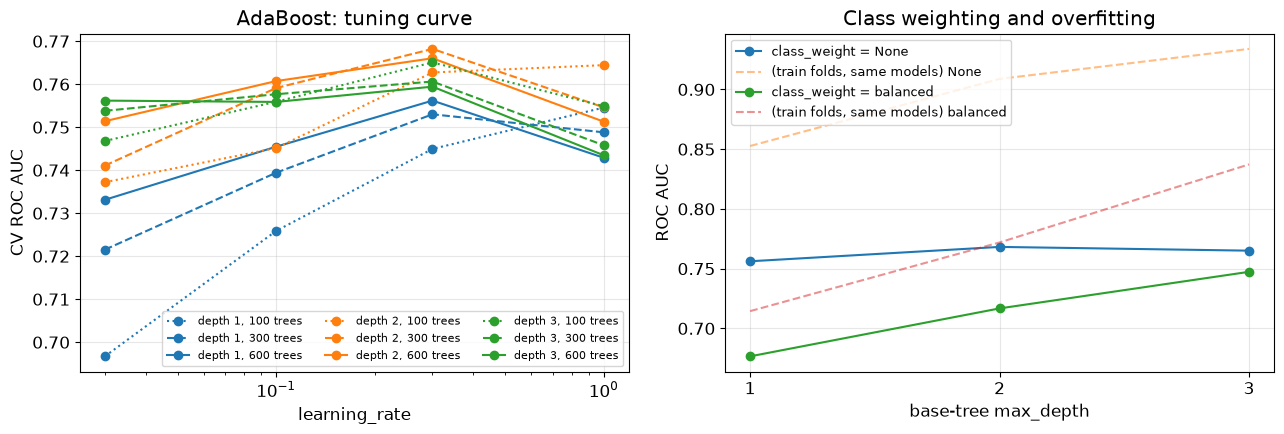

,best CV AUC,mean CV AUC over grid
weight,,
None,0.768211,0.749447
balanced,0.747359,0.705386


In [53]:
cvr_ada["weight"] = cvr_ada["param_classifier__estimator__class_weight"].apply(
    lambda w: "balanced" if w == "balanced" else "None")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for depth, g in cvr_ada.groupby("param_classifier__estimator__max_depth"):
    for n, gg in g.groupby("param_classifier__n_estimators"):
        s = gg.groupby("param_classifier__learning_rate")["mean_test_score"].max()
        axes[0].plot(s.index.astype(float), s.values, marker="o",
                     ls={100: ":", 300: "--", 600: "-"}[int(n)],
                     color={1: "C0", 2: "C1", 3: "C2"}[int(depth)],
                     label=f"depth {depth}, {n} trees")
axes[0].set_xscale("log")
axes[0].set(xlabel="learning_rate", ylabel="CV ROC AUC", title="AdaBoost: tuning curve")
axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8, ncol=3)

for w, g in cvr_ada.groupby("weight"):
    best_rows = g.loc[g.groupby("param_classifier__estimator__max_depth")["mean_test_score"].idxmax()]
    d = best_rows["param_classifier__estimator__max_depth"].astype(int)
    axes[1].plot(d, best_rows["mean_test_score"], marker="o", label=f"class_weight = {w}")
    axes[1].plot(d, best_rows["mean_train_score"], ls="--", alpha=0.5, label=f"(train folds, same models) {w}")
axes[1].set_xticks([1, 2, 3])
axes[1].set(xlabel="base-tree max_depth", ylabel="ROC AUC", title="Class weighting and overfitting")
axes[1].grid(alpha=0.3); axes[1].legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "results/adaboost_tuning_curve.png", dpi=200)
plt.show()

cvr_ada.groupby("weight")["mean_test_score"].agg(["max", "mean"]).rename(
    columns={"max": "best CV AUC", "mean": "mean CV AUC over grid"})

**Remark.** The best AdaBoost uses depth-2 trees, learning rate 0.3, 300 rounds and **no class
weighting** (CV AUC 0.768 ± 0.027, train-fold AUC 0.909). Depth-2 trees beat stumps at almost every learning rate.
This suggests pairwise interactions carry signal, as the engineered interaction flags already hinted.
A learning rate of 1.0 overfits, and 0.03 would need more rounds than the grid allows.

**Class weighting clearly hurts AdaBoost** (best CV AUC 0.747 vs 0.768; mean over the grid 0.705 vs 0.749).
Boosting already reweights the rows it gets wrong, and those are disproportionately defaults.
Adding a fixed 2.3× class weight on top over-emphasises the minority class and makes the ensemble noisier.
For AdaBoost, imbalance is therefore handled only at the decision threshold.

## 4. Evaluation
### 4.1 Test-set evaluation at three operating points
For each tuned model: out-of-fold training predictions (5-fold stratified CV) give the F1-optimal
and cost-optimal thresholds. The test set is then scored **once** at 0.5 and at both thresholds.
Test-set probabilities are saved to `outputs/predictions/<model>_test_proba.csv`.

For calibrated probabilities, theory puts the cost-optimal threshold at 1/(1+5) ≈ 0.167. The learned thresholds differ because none of the models is perfectly calibrated.

#### Logistic regression

In [54]:
op_lr = operating_points(lr_best, "logreg", "LR")

[LR] F1-optimal threshold 0.304 | cost-optimal threshold 0.188

=== LR tuned @ 0.5 | threshold = 0.500 ===
AUC 0.8163 | Precision 0.7692 | Recall 0.3333 | F1 0.4651 | Accuracy 0.7700
          pred 0  pred 1
actual 0     134       6
actual 1      40      20
=== LR tuned @ F1-optimal | threshold = 0.304 ===
AUC 0.8163 | Precision 0.5679 | Recall 0.7667 | F1 0.6525 | Accuracy 0.7550
          pred 0  pred 1
actual 0     105      35
actual 1      14      46
=== LR tuned @ cost-optimal | threshold = 0.188 ===
AUC 0.8163 | Precision 0.4390 | Recall 0.9000 | F1 0.5902 | Accuracy 0.6250
          pred 0  pred 1
actual 0      71      69
actual 1       6      54



Test AUC = 0.816, 95% bootstrap CI [0.749, 0.877]


,Model / operating point,Threshold,AUC,Precision,Recall,F1,Accuracy,TN/FP/FN/TP,Cost (FN:FP = 5:1)
0,Naive LR (7 numeric features),0.500,0.680,0.833,0.083,0.152,0.720,139/1/55/5,276.0
1,"LR untuned (C=1, L2)",0.500,0.815,0.681,0.533,0.598,0.785,125/15/28/32,155.0
2,LR tuned @ 0.5,0.500,0.816,0.769,0.333,0.465,0.770,134/6/40/20,206.0
3,LR tuned @ F1-optimal,0.304,0.816,0.568,0.767,0.652,0.755,105/35/14/46,105.0
4,LR tuned @ cost-optimal,0.188,0.816,0.439,0.900,0.590,0.625,71/69/6/54,99.0


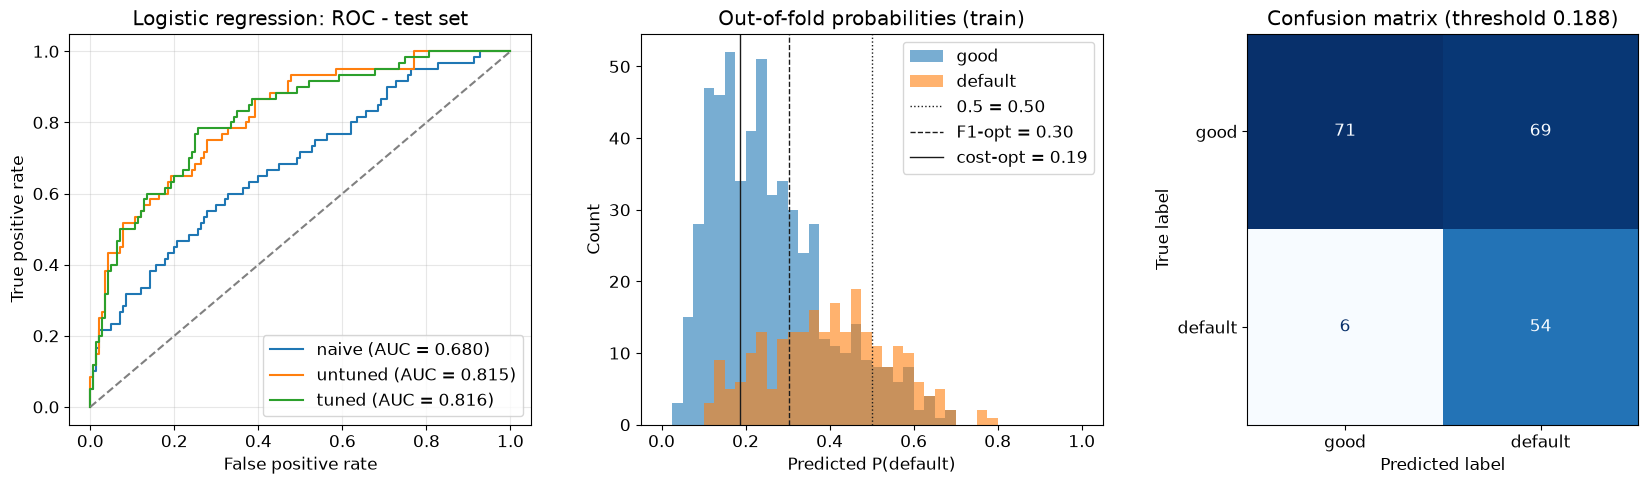

In [55]:
display(results_table([res_naive, res_lr_default, op_lr["res_05"], op_lr["res_f1"], op_lr["res_cost"]],
                      fn_cost=FN_COST))
plot_operating_points(op_lr, [(res_naive, "naive"), (res_lr_default, "untuned"), (op_lr["res_05"], "tuned")],
                      "Logistic regression", "logreg_roc_confusion.png")

**Remark.** Tuning barely changes the AUC, but the threshold changes the recall on defaults a lot.
At the cost-optimal threshold, logistic regression catches 54 of 60 defaulters (recall 0.90) at a
cost of 99, compared with 206 at 0.5.

#### Random forest

In [56]:
op_rf = operating_points(rf_best, "rf", "RF")

[RF] F1-optimal threshold 0.379 | cost-optimal threshold 0.274

=== RF tuned @ 0.5 | threshold = 0.500 ===
AUC 0.8026 | Precision 0.6316 | Recall 0.6000 | F1 0.6154 | Accuracy 0.7750
          pred 0  pred 1
actual 0     119      21
actual 1      24      36
=== RF tuned @ F1-optimal | threshold = 0.379 ===
AUC 0.8026 | Precision 0.5000 | Recall 0.7333 | F1 0.5946 | Accuracy 0.7000
          pred 0  pred 1
actual 0      96      44
actual 1      16      44
=== RF tuned @ cost-optimal | threshold = 0.274 ===
AUC 0.8026 | Precision 0.4264 | Recall 0.9167 | F1 0.5820 | Accuracy 0.6050
          pred 0  pred 1
actual 0      66      74
actual 1       5      55



Test AUC = 0.803, 95% bootstrap CI [0.733, 0.870]


,Model / operating point,Threshold,AUC,Precision,Recall,F1,Accuracy,TN/FP/FN/TP,Cost (FN:FP = 5:1)
0,RF untuned (500 trees),0.500,0.808,0.744,0.483,0.586,0.795,130/10/31/29,165.0
1,RF tuned @ 0.5,0.500,0.803,0.632,0.600,0.615,0.775,119/21/24/36,141.0
2,RF tuned @ F1-optimal,0.379,0.803,0.500,0.733,0.595,0.700,96/44/16/44,124.0
3,RF tuned @ cost-optimal,0.274,0.803,0.426,0.917,0.582,0.605,66/74/5/55,99.0


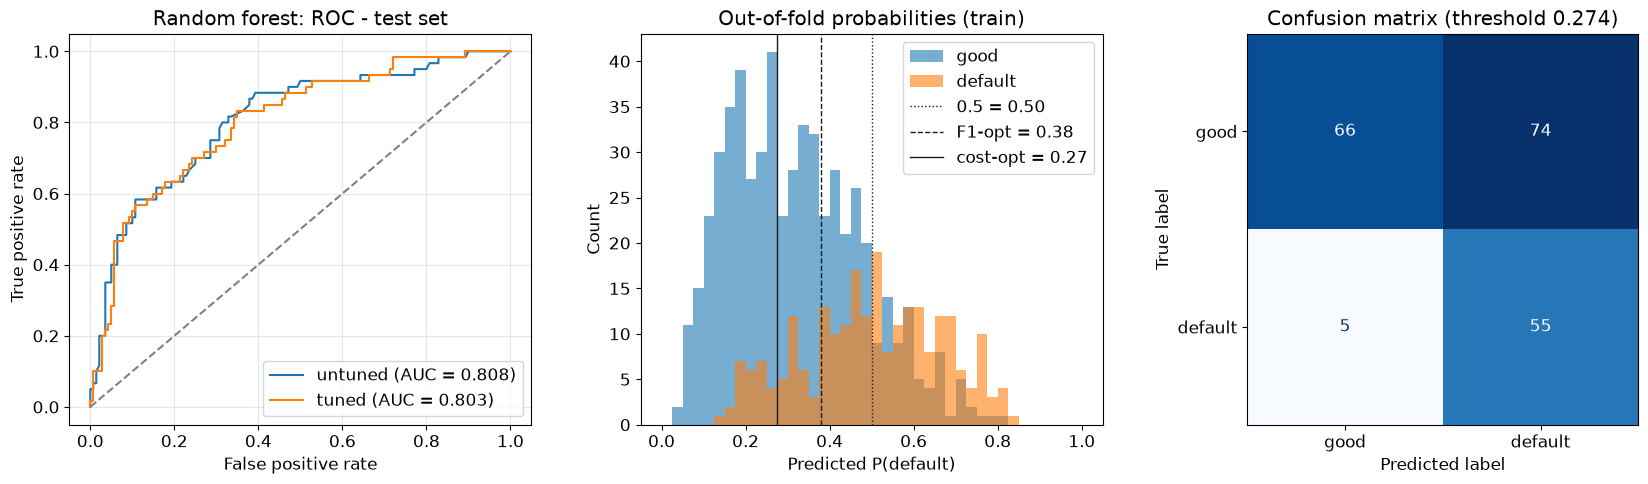

In [57]:
display(results_table([res_rf_default, op_rf["res_05"], op_rf["res_f1"], op_rf["res_cost"]], fn_cost=FN_COST))
plot_operating_points(op_rf, [(res_rf_default, "untuned"), (op_rf["res_05"], "tuned")],
                      "Random forest", "rf_roc_confusion.png")

**Remark.** Test AUC is 0.803 (95% CI 0.733–0.870), slightly below the untuned forest's 0.808.
With 200 test rows a 0.005 gap is noise. The tuned model was chosen on CV AUC, which is more reliable.
At 0.5 the tuned forest already catches more defaults than the untuned one (recall 0.60 vs 0.48)
because class weighting raises the predicted probabilities.

The cost-optimal threshold learned on the training folds is 0.274. That is above the 1/6 ≈ 0.167 that theory gives for calibrated
probabilities, because the forest's probabilities are neither calibrated nor on the unweighted scale.
At this threshold the forest catches **55 of 60 defaulters (recall 0.92)** and rejects 74 of 140 good clients.
The misclassification cost is **99**, down from 141 at 0.5.

#### AdaBoost

In [58]:
op_ada = operating_points(ada_best, "adaboost", "AdaBoost")

[AdaBoost] F1-optimal threshold 0.457 | cost-optimal threshold 0.364

=== AdaBoost tuned @ 0.5 | threshold = 0.500 ===
AUC 0.8176 | Precision 0.7500 | Recall 0.5000 | F1 0.6000 | Accuracy 0.8000
          pred 0  pred 1
actual 0     130      10
actual 1      30      30
=== AdaBoost tuned @ F1-optimal | threshold = 0.457 ===
AUC 0.8176 | Precision 0.5714 | Recall 0.6667 | F1 0.6154 | Accuracy 0.7500
          pred 0  pred 1
actual 0     110      30
actual 1      20      40
=== AdaBoost tuned @ cost-optimal | threshold = 0.364 ===
AUC 0.8176 | Precision 0.3972 | Recall 0.9333 | F1 0.5572 | Accuracy 0.5550
          pred 0  pred 1
actual 0      55      85
actual 1       4      56



Test AUC = 0.818, 95% bootstrap CI [0.748, 0.880]


,Model / operating point,Threshold,AUC,Precision,Recall,F1,Accuracy,TN/FP/FN/TP,Cost (FN:FP = 5:1)
0,"AdaBoost untuned (50 stumps, lr=1)",0.500,0.804,0.682,0.500,0.577,0.780,126/14/30/30,164.0
1,AdaBoost tuned @ 0.5,0.500,0.818,0.750,0.500,0.600,0.800,130/10/30/30,160.0
2,AdaBoost tuned @ F1-optimal,0.457,0.818,0.571,0.667,0.615,0.750,110/30/20/40,130.0
3,AdaBoost tuned @ cost-optimal,0.364,0.818,0.397,0.933,0.557,0.555,55/85/4/56,105.0


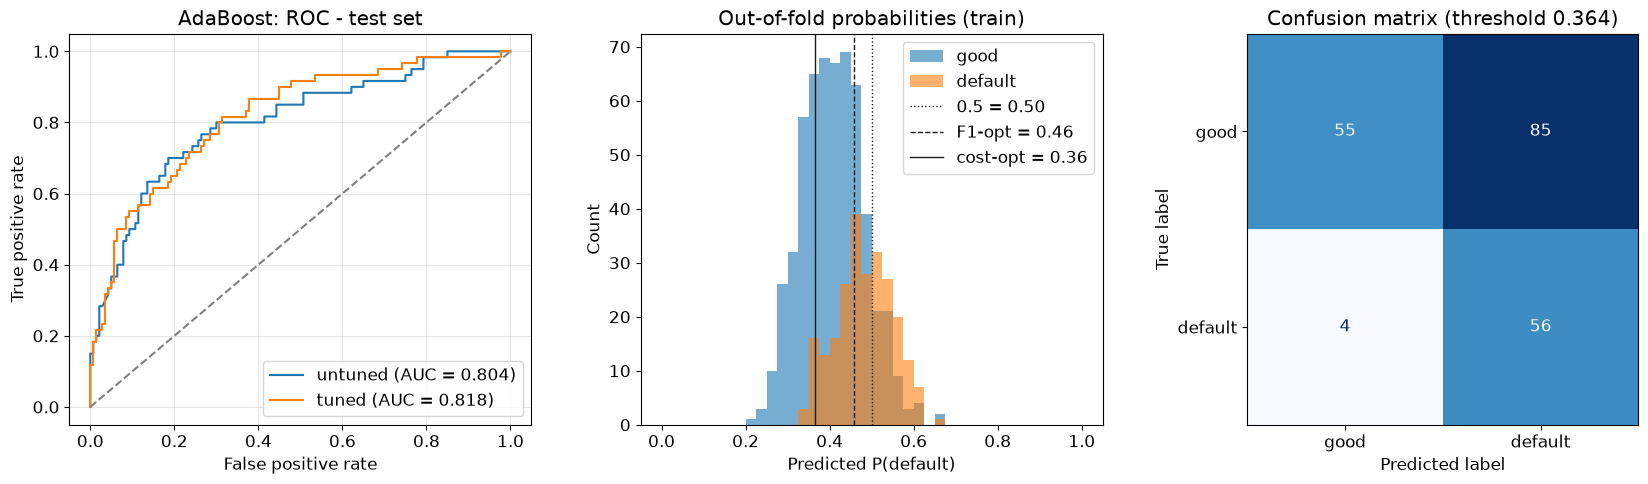

In [59]:
display(results_table([res_ada_default, op_ada["res_05"], op_ada["res_f1"], op_ada["res_cost"]],
                      fn_cost=FN_COST))
plot_operating_points(op_ada, [(res_ada_default, "untuned"), (op_ada["res_05"], "tuned")],
                      "AdaBoost", "adaboost_roc_confusion.png")

**Remark.** Test AUC is 0.818 (95% CI 0.748–0.880), the highest of the three models on the test set,
even though AdaBoost had the *lowest* CV AUC. The two estimates disagree by more than the gap between models.
This is another sign that the models cannot be separated on these data (Section 4.2).

The histogram shows the squeezed probabilities: every out-of-fold prediction lies between ≈ 0.2 and 0.67.
Thresholds must therefore be learned from the data. The cost-optimal threshold is 0.364, compared with 0.167 for calibrated
probabilities. At this threshold AdaBoost catches **56 of 60 defaulters (recall 0.93)** but rejects 85 of 140 good
clients, for a cost of **105**, down from 160 at 0.5.

### 4.2 Model comparison
The three tuned models side by side. `FINAL` collects each tuned model with its operating points and is reused in Sections 5 and 9.

In [60]:
FINAL = {"Logistic regression": (lr_best, op_lr, "logreg"),
         "Random forest": (rf_best, op_rf, "rf"),
         "AdaBoost": (ada_best, op_ada, "adaboost")}
GS = {"Logistic regression": gs_lr, "Random forest": gs_rf, "AdaBoost": gs_ada}
CVR = {"Logistic regression": cvr_lr, "Random forest": cvr_rf, "AdaBoost": cvr_ada}

#### Summary table (tuned models at the cost-optimal threshold, FN:FP = 5:1)

In [61]:
rows = []
for m, (model, op, _) in FINAL.items():
    r, r05 = op["res_cost"], op["res_05"]
    tn, fp, fn, tp = r["confusion_matrix"].ravel()
    rows.append({
        "Model": m,
        "CV AUC (mean ± sd)": f"{GS[m].best_score_:.3f} ± {CVR[m].loc[0, 'std_test_score']:.3f}",
        "Test AUC [95% CI]": f"{r['auc']:.3f} [{op['ci'][0]:.3f}, {op['ci'][1]:.3f}]",
        "Cost-opt threshold": round(op["t_cost"], 3),
        "Recall (defaults)": round(r["recall"], 3),
        "Precision": round(r["precision"], 3),
        "Good clients rejected": f"{fp}/{tn + fp}",
        "Defaults missed": f"{fn}/{fn + tp}",
        "Cost @ cost-opt": r["cost"],
        "Cost @ 0.5": r05["cost"],
    })
summary = pd.DataFrame(rows)
summary.to_csv(OUT / "results/model_comparison.csv", index=False)
summary

,Model,CV AUC (mean ± sd),Test AUC [95% CI],Cost-opt threshold,Recall (defaults),Precision,Good clients rejected,Defaults missed,Cost @ cost-opt,Cost @ 0.5
0,Logistic regression,0.769 ± 0.034,"0.816 [0.749, 0.877]",0.188,0.900,0.439,69/140,6/60,99.0,206.0
1,Random forest,0.789 ± 0.037,"0.803 [0.733, 0.870]",0.274,0.917,0.426,74/140,5/60,99.0,141.0
2,AdaBoost,0.768 ± 0.027,"0.818 [0.748, 0.880]",0.364,0.933,0.397,85/140,4/60,105.0,160.0


#### Are the AUC differences real?
Paired bootstrap on the 200 test rows: resample rows, recompute each model's AUC on the *same*
resample and take the difference. Pairing removes the variation that all models share, so this is
tighter than comparing the separate confidence intervals.

In [62]:
y_arr = y_test.values
proba = {m: op["res_05"]["y_proba"] for m, (_, op, _) in FINAL.items()}
names = list(proba)
pairs = [(a, b) for i, a in enumerate(names) for b in names[i + 1:]]
diffs = {p: [] for p in pairs}

rng = np.random.default_rng(RANDOM_STATE)
n = 0
while n < 2000:
    idx = rng.integers(0, len(y_arr), len(y_arr))
    if y_arr[idx].min() == y_arr[idx].max():
        continue
    auc = {m: roc_auc_score(y_arr[idx], proba[m][idx]) for m in names}
    for a, b in pairs:
        diffs[(a, b)].append(auc[a] - auc[b])
    n += 1

pd.DataFrame([{
    "Comparison": f"{a} − {b}",
    "AUC difference": round(roc_auc_score(y_arr, proba[a]) - roc_auc_score(y_arr, proba[b]), 3),
    "95% CI": f"[{np.percentile(d, 2.5):+.3f}, {np.percentile(d, 97.5):+.3f}]",
    "P(diff > 0)": round(float(np.mean(np.array(d) > 0)), 2),
} for (a, b), d in diffs.items()])

,Comparison,AUC difference,95% CI,P(diff > 0)
0,Logistic regression − Random forest,0.014,"[-0.019, +0.044]",0.81
1,Logistic regression − AdaBoost,-0.001,"[-0.036, +0.033]",0.45
2,Random forest − AdaBoost,-0.015,"[-0.047, +0.014]",0.17


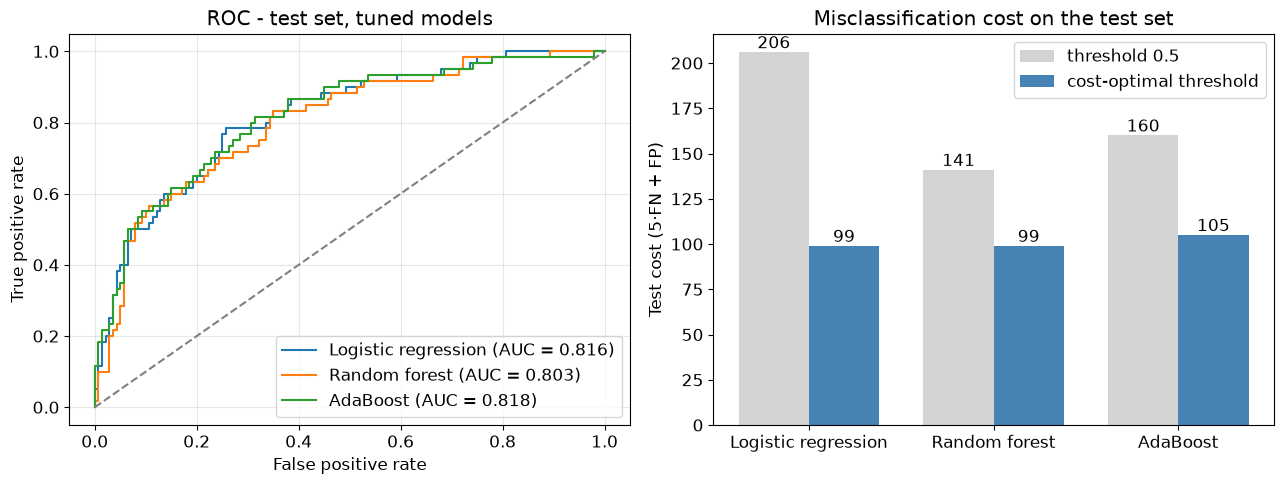

In [63]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for m in names:
    fpr, tpr, _ = roc_curve(y_arr, proba[m])
    axes[0].plot(fpr, tpr, label=f"{m} (AUC = {roc_auc_score(y_arr, proba[m]):.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="ROC - test set, tuned models")
axes[0].legend(loc="lower right"); axes[0].grid(alpha=0.3)

x, w = np.arange(len(names)), 0.38
b1 = axes[1].bar(x - w / 2, [FINAL[m][1]["res_05"]["cost"] for m in names], w,
                 label="threshold 0.5", color="lightgray")
b2 = axes[1].bar(x + w / 2, [FINAL[m][1]["res_cost"]["cost"] for m in names], w,
                 label="cost-optimal threshold", color="steelblue")
axes[1].bar_label(b1); axes[1].bar_label(b2)
axes[1].set_xticks(x, names)
axes[1].set(ylabel="Test cost (5·FN + FP)", title="Misclassification cost on the test set")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT / "results/model_comparison.png", dpi=200)
plt.show()

## 5. Interpretation
### 5.1 Logistic regression coefficients
Numeric features are standardised, so their coefficients are the change in log-odds of default per
one standard deviation. One-hot categories and engineered 0/1 flags are not scaled: their
coefficients compare the category with its absence. `odds_ratio = exp(coef)`.

0 of 70 coefficients shrunk exactly to zero


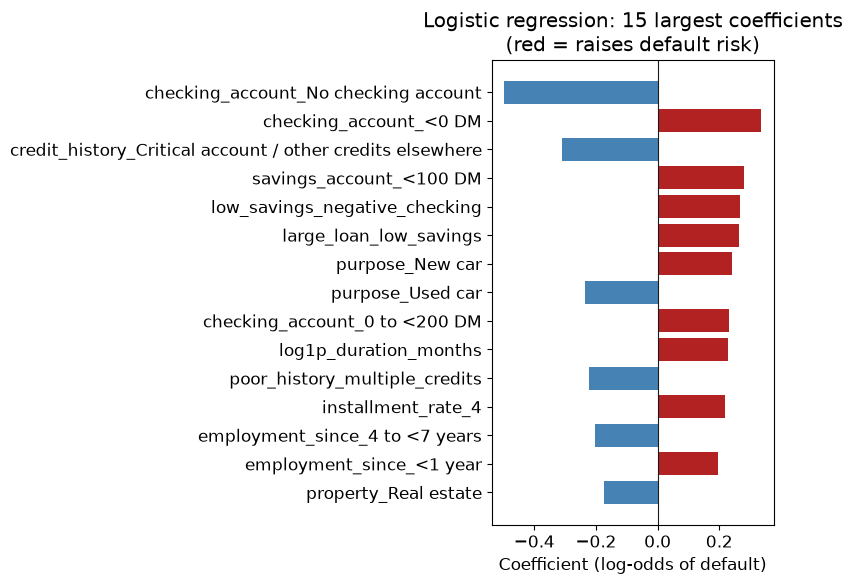

,feature,coef,odds_ratio
0,checking_account_No checking account,-0.496760,0.608499
1,checking_account_<0 DM,0.335792,1.399048
2,credit_history_Critical account / other credit...,-0.309643,0.733709
3,savings_account_<100 DM,0.281442,1.325039
4,low_savings_negative_checking,0.266263,1.305079
5,large_loan_low_savings,0.263116,1.300978
6,purpose_New car,0.241420,1.273055
7,purpose_Used car,-0.236645,0.789271
8,checking_account_0 to <200 DM,0.230355,1.259047
9,log1p_duration_months,0.228104,1.256216


In [64]:
feat_names = [n.split("__", 1)[-1] for n in lr_best.named_steps["preprocessing"].get_feature_names_out()]
coefs = pd.DataFrame({"feature": feat_names, "coef": lr_best.named_steps["classifier"].coef_.ravel()})
coefs["odds_ratio"] = np.exp(coefs["coef"])
coefs = coefs.reindex(coefs["coef"].abs().sort_values(ascending=False).index).reset_index(drop=True)
coefs.to_csv(OUT / "results/logreg_coefficients.csv", index=False)
print(f"{(coefs['coef'] == 0).sum()} of {len(coefs)} coefficients shrunk exactly to zero")

top = coefs.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top["feature"], top["coef"], color=np.where(top["coef"] > 0, "firebrick", "steelblue"))
plt.axvline(0, color="k", lw=0.8)
plt.xlabel("Coefficient (log-odds of default)")
plt.title("Logistic regression: 15 largest coefficients\n(red = raises default risk)")
plt.tight_layout()
plt.savefig(OUT / "results/logreg_coefficients.png", dpi=200)
plt.show()
coefs.head(15)

### 5.2 Permutation importance (all three models)
Tree ensembles have no coefficients, so every model is put on a common scale. **Permutation
importance** measures how much the test AUC drops when one *original* input column is shuffled
(20 repeats). Shuffling a raw column also breaks every one-hot dummy and engineered flag built from
it, so each variable gets a single score. This shows what the model relies on, not causal effects,
and correlated columns can share credit.

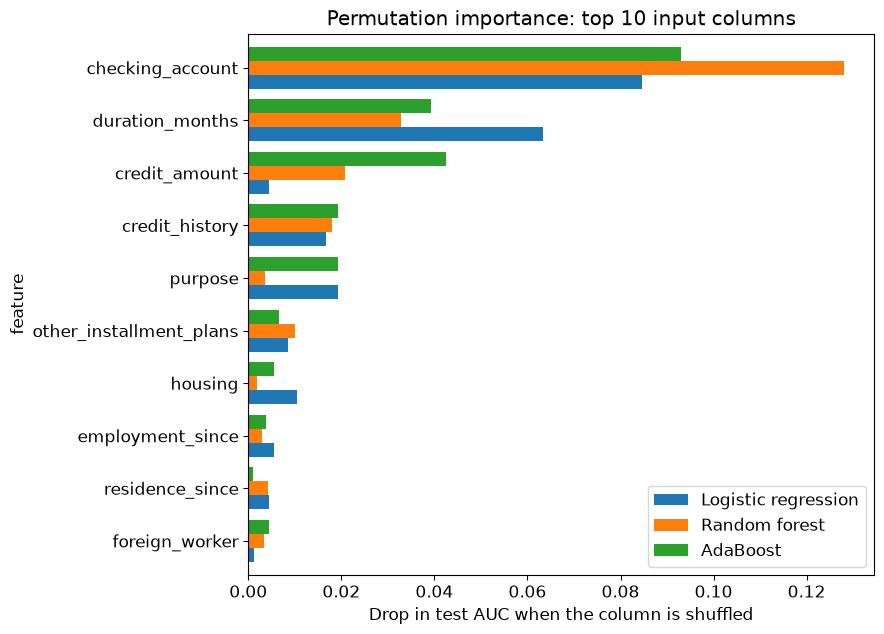

,Logistic regression,Random forest,AdaBoost
feature,,,
checking_account,0.085,0.128,0.093
duration_months,0.063,0.033,0.039
credit_amount,0.004,0.021,0.042
credit_history,0.017,0.018,0.019
purpose,0.019,0.004,0.019
other_installment_plans,0.008,0.010,0.007
housing,0.011,0.002,0.006
employment_since,0.006,0.003,0.004
residence_since,0.005,0.004,0.001


In [65]:
imps = {}
for m, (model, _, prefix) in FINAL.items():
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pi = permutation_importance(model, X_test, y_test, scoring="roc_auc", n_repeats=20,
                                    random_state=RANDOM_STATE, n_jobs=-1)
    imp = pd.DataFrame({"feature": X_test.columns, "auc_drop_mean": pi.importances_mean,
                        "auc_drop_std": pi.importances_std})
    imp = imp[(imp["auc_drop_mean"] != 0) | (imp["auc_drop_std"] != 0)]   # drop unused columns
    imp.sort_values("auc_drop_mean", ascending=False).to_csv(
        OUT / f"results/{prefix}_permutation_importance.csv", index=False)
    imps[m] = imp.set_index("feature")["auc_drop_mean"]

imp_all = pd.DataFrame(imps).fillna(0)
imp_all = imp_all.loc[imp_all.mean(axis=1).sort_values(ascending=False).index]

top = imp_all.head(10).iloc[::-1]
ax = top.plot.barh(figsize=(9, 6.5), width=0.8)
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="Drop in test AUC when the column is shuffled",
       title="Permutation importance: top 10 input columns")
plt.tight_layout()
plt.savefig(OUT / "results/permutation_importance.png", dpi=200)
plt.show()
imp_all.head(10).round(3)

**Remark.** All three models rely most on `checking_account` by a wide margin (AUC drop 0.09–0.13).
Loan `duration_months` comes second for all three and matters most to logistic regression (0.06).
The models then diverge in ways that match how they work:
- `credit_amount` matters to the tree models (0.02–0.04) but hardly to logistic regression (0.004). Its effect
  on default risk is non-linear and tied to duration, which trees can model and a linear model mostly absorbs
  through duration and the engineered amount/duration features.
- `purpose` matters to logistic regression and AdaBoost (≈ 0.02) but little to the random forest.
- `credit_history` is equally important to all three (≈ 0.02).

Beyond the top six columns the drops are about the size of their standard deviations and cannot be ranked reliably.

### 5.3 SHAP analysis
SHAP values measure each feature's contribution to the predicted default probability of Logistic Regression, Random Forest and AdaBoost. They show how specific categorical levels and engineered predictors influence individual predictions. SHAP is computed on the encoded features with a permutation explainer, using 50 training rows as background, for all 200 test clients. One-hot columns are then summed back into their original variable. We report:
1. Mean absolute SHAP values, to assess global feature importance.
2. Beeswarm plots, to show the direction of each effect and differences in feature reliance across the three models.
3. Relative SHAP importance (%), to compare models on a common scale.

In [66]:

#Calculate SHAP on transformed features
N_BACKGROUND = 50
N_EXPLAIN = min(200, len(X_test))
SHAP = {}
SHAP_FEATURES = {}
SHAP_DATA = {}
SHAP_GROUPS = {}

for name, (model, _, prefix) in FINAL.items():
    print(f"Calculating SHAP for {name}...")
    engineer = model.named_steps["feature_engineering"]
    preprocessor = model.named_steps["preprocessing"]
    classifier = model.named_steps["classifier"]
    X_train_fe = engineer.transform(X_train)
    X_test_fe = engineer.transform(X_test)
    # Apply the fitted preprocessing 
    X_train_encoded = np.asarray(
        preprocessor.transform(X_train_fe),
        dtype=float
    )
    X_test_encoded = np.asarray(
        preprocessor.transform(X_test_fe),
        dtype=float
    )
    feature_names = preprocessor.get_feature_names_out()
    groups = []
    for transformer_name, transformer, columns in preprocessor.transformers_:
        if transformer_name == "remainder":
            continue
        if transformer_name == "cat":
            onehot = transformer.named_steps["onehot"]
            for col, categories in zip(columns, onehot.categories_):
                groups.extend([col] * len(categories))
        else:
            groups.extend(list(columns))
    assert len(groups) == X_train_encoded.shape[1]
    rng = np.random.default_rng(RANDOM_STATE)
    bg_idx = rng.choice(
        len(X_train_encoded),
        size=min(N_BACKGROUND, len(X_train_encoded)),
        replace=False
    )
    background = X_train_encoded[bg_idx]
    X_explain = X_test_encoded[:N_EXPLAIN]
    def predict_default(X, fitted_classifier=classifier):
        return fitted_classifier.predict_proba(X)[:, 1]
    explainer = shap.Explainer(
        predict_default,
        shap.maskers.Independent(background),
        algorithm="permutation"
    )
    values = explainer(
        X_explain,
        max_evals=2 * X_explain.shape[1] + 1
    )
    SHAP[name] = values
    SHAP_FEATURES[name] = list(feature_names)
    SHAP_DATA[name] = X_explain
    SHAP_GROUPS[name] = groups
    print(
        f"Completed: {name} | "
        f"{X_explain.shape[1]} transformed features"
    )
print("SHAP completed for all three models.")



Calculating SHAP for Logistic regression...


Completed: Logistic regression | 70 transformed features
Calculating SHAP for Random forest...


Completed: Random forest | 70 transformed features
Calculating SHAP for AdaBoost...


Completed: AdaBoost | 70 transformed features
SHAP completed for all three models.


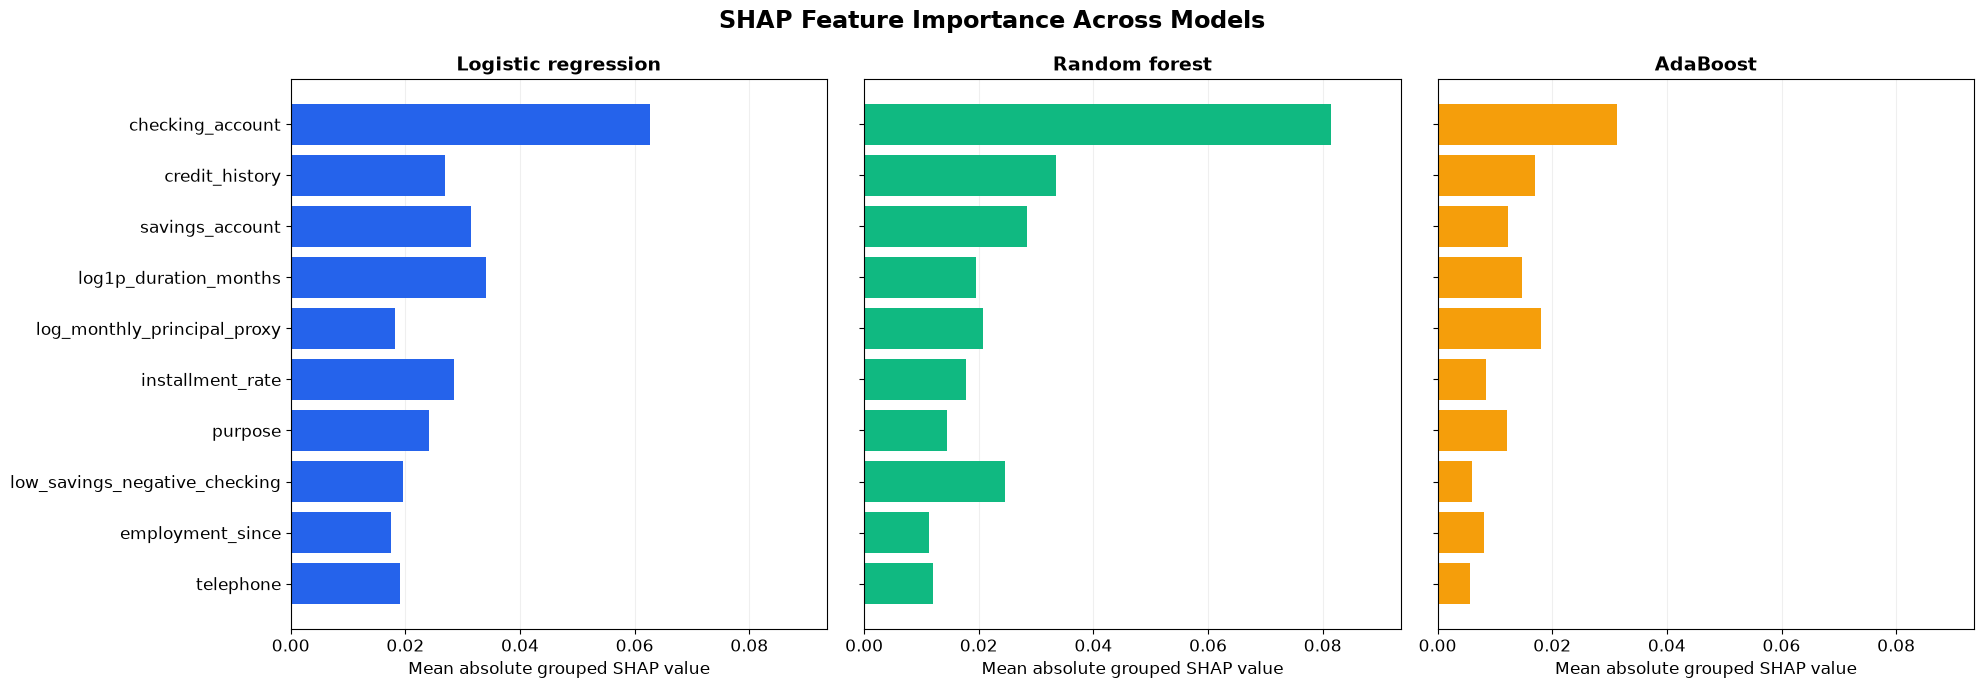

,Logistic regression,Random forest,AdaBoost
checking_account,0.0627,0.0814,0.0313
credit_history,0.0269,0.0334,0.0170
savings_account,0.0315,0.0285,0.0123
log1p_duration_months,0.0340,0.0195,0.0147
log_monthly_principal_proxy,0.0183,0.0207,0.0180
installment_rate,0.0284,0.0177,0.0085
purpose,0.0241,0.0145,0.0121
low_savings_negative_checking,0.0196,0.0246,0.0060
employment_since,0.0176,0.0114,0.0081
telephone,0.0191,0.0120,0.0056


In [67]:
#SHAP Feature Importance
grouped_shap = {}

for name in SHAP:
    values = SHAP[name].values
    groups = SHAP_GROUPS[name]
    unique_groups = list(dict.fromkeys(groups))
    grouped_values = np.column_stack([
        values[:, np.array(groups) == group].sum(axis=1)
        for group in unique_groups
    ])
    grouped_shap[name] = pd.DataFrame(
        grouped_values,
        columns=unique_groups
    )

# Mean absolute grouped SHAP importance
importance = pd.DataFrame({
    name: df.abs().mean(axis=0)
    for name, df in grouped_shap.items()
}).fillna(0)

top_features = (
    importance.mean(axis=1)
    .nlargest(10)
    .index.tolist()
)

models = list(SHAP.keys())
colors = ["#2563EB", "#10B981", "#F59E0B"]

fig, axes = plt.subplots(
    1, 3, figsize=(20, 7),
    sharex=True, sharey=True
)

max_value = importance.loc[top_features].max().max()
for ax, name, color in zip(axes, models, colors):
    values = importance.loc[top_features, name]
    ax.barh(
        top_features[::-1],
        values.iloc[::-1],
        color=color
    )
    ax.set_title(name, fontsize=14, fontweight="bold")
    ax.set_xlabel("Mean absolute grouped SHAP value")
    ax.set_xlim(0, max_value * 1.15)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
fig.suptitle(
    "SHAP Feature Importance Across Models",
    fontsize=17, fontweight="bold"
)

plt.tight_layout()
plt.savefig(
    OUT / "results/shap_grouped_importance.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

display(importance.loc[top_features].round(4))


As seen from the graph, it is clear that checking account plays a huge role in the predicting default probability. The other features vary with the model.

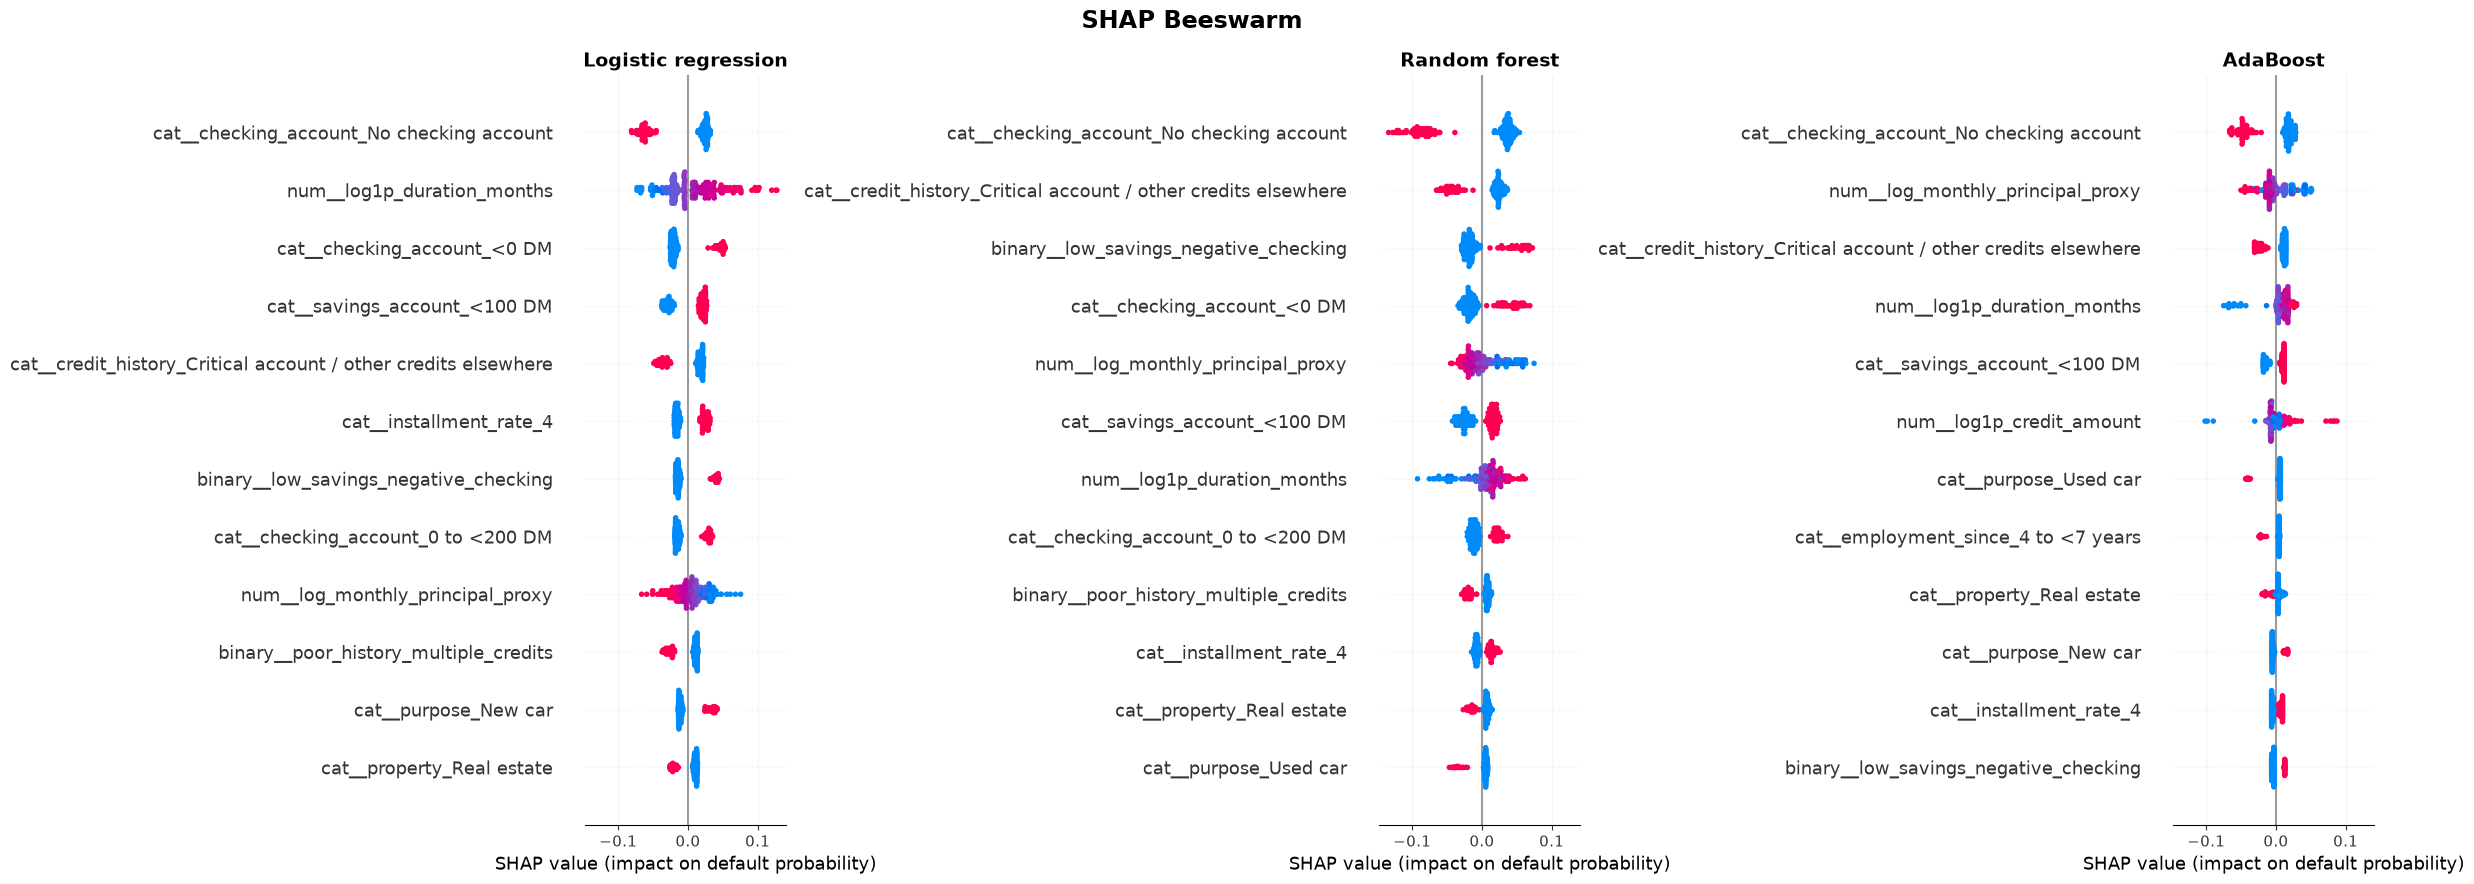

In [68]:

# SHAP Beeswarm
fig, axes = plt.subplots(
    1, 3, figsize=(24, 9),
    sharex=True
)
for ax, name in zip(axes, models):
    values = SHAP[name]
    # Rank transformed features by mean absolute SHAP
    feature_importance = np.abs(values.values).mean(axis=0)
    indices = np.argsort(feature_importance)[::-1][:12]
    explanation = shap.Explanation(
        values=values.values[:, indices],
        base_values=values.base_values,
        data=SHAP_DATA[name][:, indices],
        feature_names=[
            SHAP_FEATURES[name][i]
            for i in indices
        ]
    )
    plt.sca(ax)
    shap.plots.beeswarm(
        explanation,
        max_display=12,
        show=False,
        plot_size=None,
        color_bar=False
    )
    ax.set_title(name, fontsize=14, fontweight="bold")
    ax.set_xlabel("SHAP value (impact on default probability)")
    ax.grid(axis="x", alpha=0.15)
fig.suptitle(
    "SHAP Beeswarm",
    fontsize=17,
    fontweight="bold"
)
plt.tight_layout()
plt.savefig(
    OUT / "results/shap_encoded_beeswarm.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


Evidently, we see that across the board, Checking Account is consistently influential. More specifically, we see that borrowers with no checking account receive a negative SHAP contribution, reducing their predicted default probability, which appears to be rather counterintuitive, but aligns well with the LR coefficients in Section 5.1.

,Logistic regression,Random forest,AdaBoost
checking_account,15.04,22.81,16.81
credit_history,6.45,9.38,9.13
savings_account,7.55,7.98,6.64
log1p_duration_months,8.16,5.48,7.91
log_monthly_principal_proxy,4.38,5.81,9.70
installment_rate,6.82,4.97,4.58
purpose,5.76,4.06,6.51
low_savings_negative_checking,4.70,6.91,3.24
employment_since,4.21,3.19,4.38
telephone,4.59,3.37,3.00


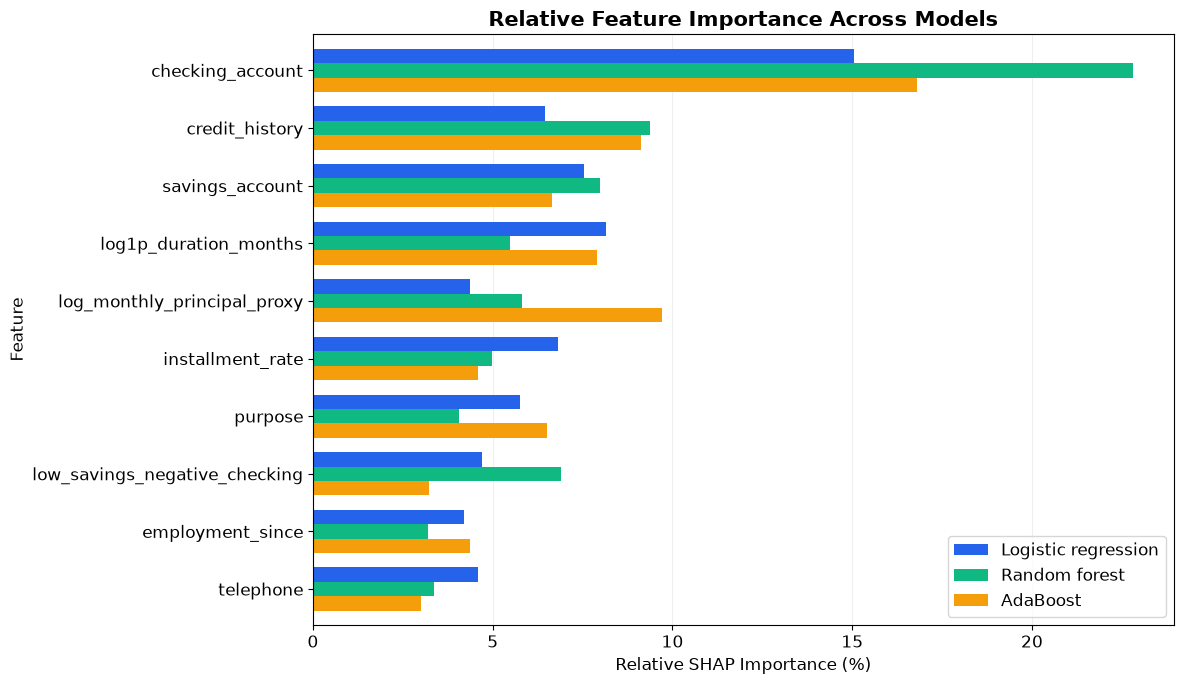

In [69]:
#Relative SHAP Importance (%)
importance_pct = (
    importance.div(importance.sum(axis=0), axis=1) * 100
)
comparison = (
    importance_pct.loc[top_features]
    .round(2)
)
display(comparison)

ax = comparison.plot(
    kind="barh",
    figsize=(12, 7),
    color=["#2563EB", "#10B981", "#F59E0B"],
    width=0.75
)
ax.set_xlabel("Relative SHAP Importance (%)")
ax.set_ylabel("Feature")
ax.set_title(
    "Relative Feature Importance Across Models",
    fontsize=15,
    fontweight="bold"
)
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


Diving deeper into Checking Account, we see that while all 3 models identify checking account status as the most influential predictor, Random Forest relies on it considerably more heavily than the other 2, with almost 30% of its total SHAP importance. 
In addition, Loan duration is more influential in Logistic Regression while AdaBoost looks at credit amount significantly more than the rest. This suggests how different models capture nonlinear relationships involving loan amounts. 

## 6. Fairness analysis
### 6.1 Cost-sensitive baseline and fairness audit
This audit uses a simple cost-sensitive logistic regression on the original features from Section 1 (no engineered features), fitted on the same training rows. Gender and age are excluded from the model and used only to compare outcomes across groups on the test set.

Positive class: **Bad = 1**, Good = 0. Approval means predicted Good, not an observed lending decision.

False approval (Bad predicted Good) costs 5; false denial (Good predicted Bad) costs 1. For p = P(Bad), approval costs 5p and denial costs 1-p. Predict Bad when p >= 1/6; approve otherwise. This fixed rule assumes calibrated probabilities; the baseline is not separately calibrated. No test labels are used to select the threshold.

- Total cost = 5 x false approvals + false denials = 5 x FN + FP.
- Approval rate = predicted Good / group size.
- FPR = Good predicted Bad / actually Good (false denial).
- FNR = Bad predicted Good / actually Bad (false approval).

Compare with the standard 0.5 threshold. Small group denominators make estimates uncertain. Tune/calibrate final models within training data only.


In [70]:
sensitive_and_metadata = {
    "original_row_index", "original_label", "credit_risk", "gender_group", "age_group",
    "age_years", "personal_status_sex",
}
model_numeric = [c for c in numeric_columns if c not in sensitive_and_metadata]
model_categorical = [c for c in categorical_columns if c not in sensitive_and_metadata]
model_features = model_numeric + model_categorical

preprocessor = ColumnTransformer(transformers=[
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), model_numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), model_categorical),
])
baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
baseline.fit(train_df[model_features], train_df["credit_risk"])
y_true = test_df["credit_risk"].to_numpy()
FALSE_APPROVAL_COST = 5
FALSE_DENIAL_COST = 1
BAD_RISK_THRESHOLD = FALSE_DENIAL_COST / (FALSE_APPROVAL_COST + FALSE_DENIAL_COST)
probability_bad = baseline.predict_proba(test_df[model_features])[:, list(baseline.classes_).index(1)]
y_pred = (probability_bad >= BAD_RISK_THRESHOLD).astype(int)
y_pred_standard = (probability_bad >= 0.5).astype(int)

def decision_cost_summary(truth, prediction, policy, threshold):
    truth, prediction = np.asarray(truth), np.asarray(prediction)
    fp = int(((truth == 0) & (prediction == 1)).sum())
    fn = int(((truth == 1) & (prediction == 0)).sum())
    total = FALSE_APPROVAL_COST * fn + FALSE_DENIAL_COST * fp
    return {"policy": policy, "threshold_bad": threshold,
            "false_approvals": fn, "false_denials": fp,
            "total_cost": total, "mean_cost": total / len(truth),
            "accuracy": float((truth == prediction).mean()),
            "approval_rate": float((prediction == 0).mean())}

cost_comparison = pd.DataFrame([
    decision_cost_summary(y_true, y_pred_standard, "Standard threshold", 0.5),
    decision_cost_summary(y_true, y_pred, "Cost-matrix threshold", BAD_RISK_THRESHOLD),
])
cost_comparison.to_csv(OUT / "baseline_cost_comparison.csv", index=False)
display(cost_comparison.round(4))
print(f"Predict Bad when P(Bad) >= {BAD_RISK_THRESHOLD:.6f}")
print(f"Cost-sensitive baseline test accuracy: {(y_true == y_pred).mean():.3f}")
print(f"Model predictors ({len(model_features)}): {model_features}")

,policy,threshold_bad,false_approvals,false_denials,total_cost,mean_cost,accuracy,approval_rate
0,Standard threshold,0.5000,28,16,156,0.780,0.780,0.760
1,Cost-matrix threshold,0.1667,10,61,111,0.555,0.645,0.445


Predict Bad when P(Bad) >= 0.166667
Cost-sensitive baseline test accuracy: 0.645
Model predictors (18): ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'existing_credits', 'people_liable', 'checking_account', 'credit_history', 'purpose', 'savings_account', 'employment_since', 'other_debtors', 'property', 'other_installment_plans', 'housing', 'job', 'telephone', 'foreign_worker']


In [71]:
def group_fairness_table(frame, truth, prediction, group_column, dimension):
    audit = frame[[group_column]].copy()
    audit["actual_good"] = np.asarray(truth) == 0
    audit["predicted_good"] = np.asarray(prediction) == 0
    rows = []
    for group, part in audit.groupby(group_column, dropna=False, observed=True):
        actual_good = part["actual_good"]
        predicted_good = part["predicted_good"]
        actual_bad = ~actual_good
        approved = predicted_good
        false_approval_count = int((actual_bad & approved).sum())
        false_denial_count = int((actual_good & ~predicted_good).sum())
        bad_count = int(actual_bad.sum())
        good_count = int(actual_good.sum())
        rows.append({
            "dimension": dimension,
            "group": str(group),
            "n": int(len(part)),
            "actual_good_n": good_count,
            "actual_bad_n": bad_count,
            "predicted_approved_n": int(approved.sum()),
            "approval_rate": float(approved.mean()),
            "false_approval_n": false_approval_count,
            "false_approval_denominator_bad": bad_count,
            "false_negative_rate": false_approval_count / bad_count if bad_count else np.nan,
            "total_cost": FALSE_APPROVAL_COST * false_approval_count + FALSE_DENIAL_COST * false_denial_count,
            "mean_cost": (FALSE_APPROVAL_COST * false_approval_count + FALSE_DENIAL_COST * false_denial_count) / len(part),
            "false_denial_n": false_denial_count,
            "false_denial_denominator_good": good_count,
            "false_positive_rate": false_denial_count / good_count if good_count else np.nan,
        })
    return pd.DataFrame(rows)

gender_fairness = group_fairness_table(test_df, y_true, y_pred, "gender_group", "gender")
age_fairness = group_fairness_table(test_df, y_true, y_pred, "age_group", "age")
fairness = pd.concat([gender_fairness, age_fairness], ignore_index=True)
age_order = {v: i for i, v in enumerate(["<25", "25-34", "35-44", "45-54", "55+"])}
fairness["_order"] = fairness["group"].map(age_order).fillna(-1)
fairness = fairness.sort_values(["dimension", "_order", "group"]).drop(columns="_order").reset_index(drop=True)
fairness.to_csv(OUT / "fairness_by_group.csv", index=False)
display(fairness.round(4))


for dimension, result in fairness.groupby("dimension"):
    print(f"{dimension.title()} max-minus-min rate gaps (descriptive only):")
    display((result[["approval_rate", "false_positive_rate", "false_negative_rate"]].max()
             - result[["approval_rate", "false_positive_rate", "false_negative_rate"]].min())
            .rename("gap").to_frame())

,dimension,group,n,actual_good_n,actual_bad_n,predicted_approved_n,approval_rate,false_approval_n,false_approval_denominator_bad,false_negative_rate,total_cost,mean_cost,false_denial_n,false_denial_denominator_good,false_positive_rate
0,age,<25,30,15,15,5,0.1667,1,15,0.0667,16,0.5333,11,15,0.7333
1,age,25-34,78,54,24,33,0.4231,3,24,0.1250,39,0.5000,24,54,0.4444
2,age,35-44,47,36,11,26,0.5532,4,11,0.3636,34,0.7234,14,36,0.3889
3,age,45-54,28,20,8,16,0.5714,2,8,0.2500,16,0.5714,6,20,0.3000
4,age,55+,17,15,2,9,0.5294,0,2,0.0000,6,0.3529,6,15,0.4000
5,gender,Female,57,37,20,22,0.3860,2,20,0.1000,27,0.4737,17,37,0.4595
6,gender,Male,143,103,40,67,0.4685,8,40,0.2000,84,0.5874,44,103,0.4272


Age max-minus-min rate gaps (descriptive only):


,gap
approval_rate,0.404762
false_positive_rate,0.433333
false_negative_rate,0.363636


Gender max-minus-min rate gaps (descriptive only):


,gap
approval_rate,0.082567
false_positive_rate,0.032275
false_negative_rate,0.100000


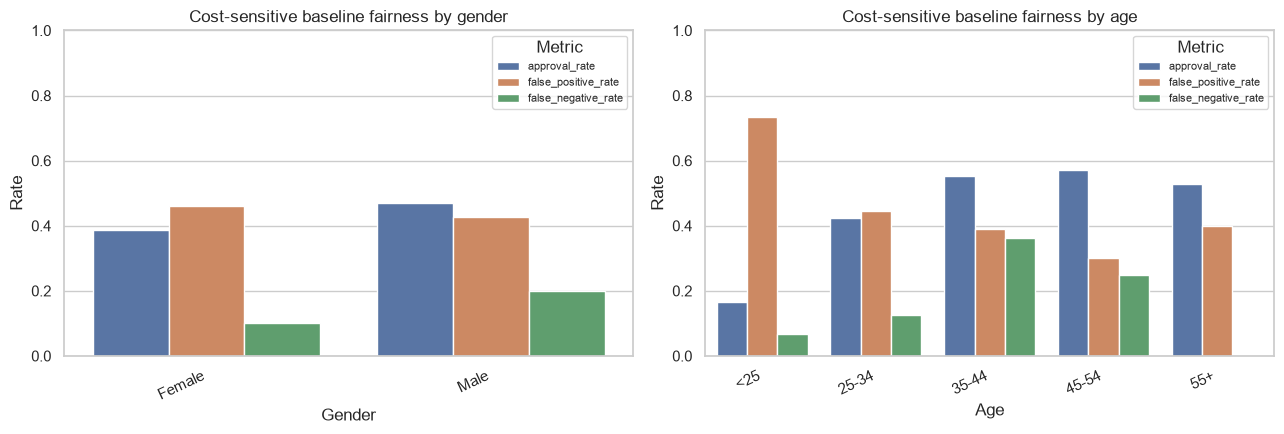

Fairness results saved to: /Users/sarah/Desktop/DSE4212-Creditscoring/outputs/fairness_by_group.csv


In [72]:
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, dimension in zip(axes, ["gender", "age"]):
    subset = fairness[fairness["dimension"] == dimension].melt(
        id_vars=["group", "n"],
        value_vars=["approval_rate", "false_positive_rate", "false_negative_rate"],
        var_name="metric", value_name="rate",
    )
    sns.barplot(data=subset, x="group", y="rate", hue="metric", ax=ax)
    ax.set(title=f"Cost-sensitive baseline fairness by {dimension}", xlabel=dimension.title(), ylabel="Rate")
    ax.set_ylim(0, 1)
    ax.legend(title="Metric", fontsize=8)
    for tick in ax.get_xticklabels():
        tick.set_rotation(25)
        tick.set_ha("right")
plt.tight_layout()
show_and_save("fairness_by_group")
print(f"Fairness results saved to: {(OUT / 'fairness_by_group.csv').resolve()}")

In [73]:
# Export predictions so teammates can independently reproduce the fairness table.
prediction_audit = test_df[["original_row_index", "gender_group", "age_group", "credit_risk"]].copy()
prediction_audit["probability_bad"] = probability_bad
prediction_audit["predicted_bad"] = y_pred
prediction_audit["predicted_bad_standard"] = y_pred_standard
prediction_audit["decision_cost"] = np.where((y_true == 1) & (y_pred == 0), FALSE_APPROVAL_COST,
                                           np.where((y_true == 0) & (y_pred == 1), FALSE_DENIAL_COST, 0))
assert prediction_audit["decision_cost"].sum() == cost_comparison.iloc[1]["total_cost"]
prediction_audit.to_csv(OUT / "baseline_test_predictions.csv", index=False)
split_membership = pd.concat([train_df[["original_row_index"]].assign(split="train"),
                              test_df[["original_row_index"]].assign(split="test")]).sort_values("original_row_index")
split_membership.to_csv(OUT / "split_membership.csv", index=False)


### 6.2 Fairness of the tuned models
Section 6.1 audits a simple baseline. The decisions that matter are those of the three **tuned** models at their **cost-optimal thresholds** (Section 4.1), so the same audit is repeated for them with the same `group_fairness_table` function. The three rates per group:
- **Approval rate:** the share predicted good (*demographic parity*).
- **False-denial rate (FPR):** the share of *good* clients wrongly rejected. Comparing it across groups is the *equal-opportunity* test, which is not affected by one group simply defaulting more often.
- **False-approval rate (FNR):** the share of defaulters approved (the lender's risk).

In [74]:
# Fairness audit of the tuned models at their cost-optimal thresholds (test set)
tuned_fairness = []
for m, (model, op, prefix) in FINAL.items():
    pred = (op["res_cost"]["y_proba"] >= op["t_cost"]).astype(int)   # same rule as evaluate()
    for col, dim in [("gender_group", "gender"), ("age_group", "age")]:
        t = group_fairness_table(test, y_test.values, pred, col, dim)
        t.insert(0, "model", m)
        tuned_fairness.append(t)
tuned_fairness = pd.concat(tuned_fairness, ignore_index=True)
tuned_fairness.to_csv(OUT / "results/fairness_tuned_models.csv", index=False)

group_order = ["Female", "Male", "<25", "25-34", "35-44", "45-54", "55+"]
by_model = {m: tuned_fairness[tuned_fairness["model"] == m].set_index("group").reindex(group_order) for m in FINAL}
first = by_model["Logistic regression"]
fair_view = pd.DataFrame({"n": first["n"], "bad rate": first["actual_bad_n"] / first["n"]})
for metric, label in [("approval_rate", "approval"), ("false_positive_rate", "false denial"),
                      ("false_negative_rate", "false approval")]:
    for m in FINAL:
        fair_view[f"{label} | {m}"] = by_model[m][metric]
fair_view.round(2)

,n,bad rate,approval | Logistic regression,approval | Random forest,approval | AdaBoost,false denial | Logistic regression,false denial | Random forest,false denial | AdaBoost,false approval | Logistic regression,false approval | Random forest,false approval | AdaBoost
group,,,,,,,,,,,
Female,57,0.35,0.32,0.30,0.30,0.54,0.59,0.57,0.05,0.10,0.05
Male,143,0.28,0.41,0.38,0.29,0.48,0.50,0.62,0.12,0.08,0.08
<25,30,0.50,0.10,0.13,0.10,0.80,0.80,0.87,0.00,0.07,0.07
25-34,78,0.31,0.37,0.32,0.22,0.52,0.56,0.69,0.12,0.04,0.00
35-44,47,0.23,0.47,0.43,0.43,0.42,0.50,0.50,0.09,0.18,0.18
45-54,28,0.29,0.54,0.50,0.39,0.35,0.35,0.50,0.25,0.12,0.12
55+,17,0.12,0.47,0.47,0.47,0.47,0.47,0.47,0.00,0.00,0.00


In [75]:
# Are the false-denial gaps larger than chance? Fisher exact test on good clients only
from scipy.stats import fisher_exact

tests = []
for m in FINAL:
    t = by_model[m]
    for label, a, b in [("Age <25 vs 25+", ["<25"], ["25-34", "35-44", "45-54", "55+"]),
                        ("Female vs Male", ["Female"], ["Male"])]:
        den_a, good_a = t.loc[a, "false_denial_n"].sum(), t.loc[a, "actual_good_n"].sum()
        den_b, good_b = t.loc[b, "false_denial_n"].sum(), t.loc[b, "actual_good_n"].sum()
        _, p_value = fisher_exact([[den_a, good_a - den_a], [den_b, good_b - den_b]])
        tests.append({"Model": m, "Comparison": label,
                      "False denials (group 1)": f"{den_a}/{good_a} = {den_a / good_a:.2f}",
                      "False denials (group 2)": f"{den_b}/{good_b} = {den_b / good_b:.2f}",
                      "Fisher p-value": round(p_value, 3)})
pd.DataFrame(tests)

,Model,Comparison,False denials (group 1),False denials (group 2),Fisher p-value
0,Logistic regression,Age <25 vs 25+,12/15 = 0.80,57/125 = 0.46,0.014
1,Logistic regression,Female vs Male,20/37 = 0.54,49/103 = 0.48,0.567
2,Random forest,Age <25 vs 25+,12/15 = 0.80,62/125 = 0.50,0.030
3,Random forest,Female vs Male,22/37 = 0.59,52/103 = 0.50,0.443
4,AdaBoost,Age <25 vs 25+,13/15 = 0.87,72/125 = 0.58,0.047
5,AdaBoost,Female vs Male,21/37 = 0.57,64/103 = 0.62,0.564


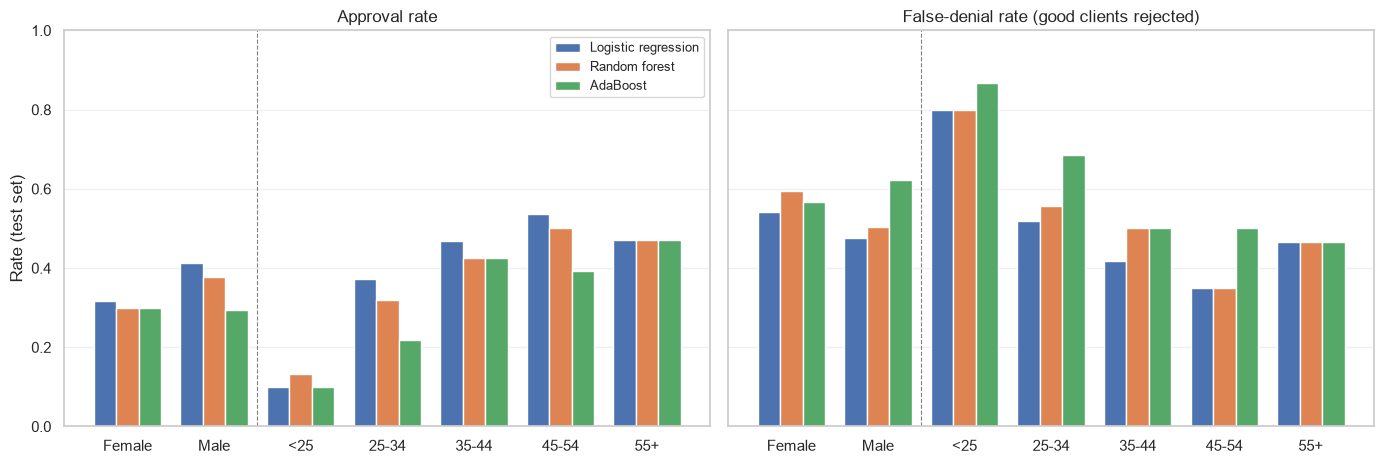

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), sharey=True)
x, w = np.arange(len(group_order)), 0.26
for ax, metric, title in zip(axes, ["approval_rate", "false_positive_rate"],
                             ["Approval rate", "False-denial rate (good clients rejected)"]):
    for k, m in enumerate(FINAL):
        ax.bar(x + (k - 1) * w, by_model[m][metric], w, label=m)
    ax.axvline(1.5, color="gray", lw=0.8, ls="--")   # gender | age
    ax.set_xticks(x, group_order)
    ax.set_ylim(0, 1)
    ax.set_title(title)
    ax.grid(axis="y", alpha=0.3)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Rate (test set)")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.savefig(OUT / "results/fairness_tuned_models.png", dpi=200)
plt.show()

**Remark.**
- **Gender: no evidence of unequal treatment.** Women are approved 30–32% of the time and men 29–41%. False-denial rates are 54–59% for women and 48–62% for men, and no gap is significant (Fisher p = 0.44–0.57). The lower approval rate for women under LR and RF is consistent with their higher observed bad rate in the test set (35% vs 28%).
- **Age: young applicants are clearly disadvantaged.** Under-25s are approved only 10–13% of the time, against 22–54% in the other age bands. Of the 15 creditworthy under-25s, 12–13 are rejected (80–87%), against 46–58% of creditworthy applicants aged 25+. The gap is significant for all three models (Fisher p = 0.014–0.047).
- **The gap comes from the data, not the algorithm.** Age is not a model input, and all three models show the same pattern. Young applicants tend to have short employment and credit histories and low savings, and these features act as proxies for age. Part of the gap reflects genuinely higher risk: half of the under-25s in the test set defaulted, against 26% of older applicants. But the false-denial rate looks only at *good* clients, so creditworthy young borrowers still bear a disproportionate share of the errors.
- **The tuned models widen the gap relative to the baseline** (73% false denial for under-25s in Section 6.1), because their cost-optimal thresholds reject more applicants overall.
- **Caveats.** Only 30 test applicants are under 25 (15 of them good), the analysis uses a single split, and the gender variable is derived from a combined status/sex attribute that contains no single women.

## 7. Conclusions
- **No model is clearly better at ranking borrowers.** Test AUCs are 0.803–0.818 and every paired AUC
  difference has a 95% CI that contains 0. Random forest has the best CV AUC (0.789) but the lowest
  test AUC, and AdaBoost the reverse. This 200-row test set cannot separate the three models.
- **The threshold matters far more than the model.** Moving from 0.5 to the cost-optimal threshold
  cuts the test cost by 30–52% for every model (LR 206 → 99, RF 141 → 99, AdaBoost 160 → 105).
  All three models catch 90–93% of defaulters, at the price of rejecting about half of the good clients.
- **Class imbalance.** Reweighting classes during training barely changed the forest's AUC and hurt
  AdaBoost's. The effective lever for the 30% default rate and the 5:1 cost ratio is the decision threshold.
- **The models agree on the main drivers:** checking-account status first, then loan duration and credit
  history. The tree models also use the loan amount, which logistic regression barely needs (Section 5.2).
- **Fairness by age needs attention.** At the cost-optimal thresholds all three models reject 80–87% of
  creditworthy applicants under 25, against 46–58% of those aged 25+ (Fisher p = 0.014–0.047), although age is
  not a model input. Gender gaps are small and not significant (Section 6.2).
- **Recommendation:** at equal cost, logistic regression is the simplest model to explain and
  audit, with coefficients and odds ratios. The tree ensembles do not earn their extra complexity on this dataset.

## 8. Business Recommendations
Based on the model evaluation and SHAP analysis, several actionable recommendations can be proposed to improve loan approval policies while balancing credit risk, profitability and fairness.

1. Prioritise Financial Liquidity in Credit Risk Assessment
Checking account status consistently emerges as the most influential predictor across Logistic Regression, Random Forest and AdaBoost, accounting for approximately 20–29% of relative SHAP importance. Savings account status is also consistently important, contributing approximately 10–12%. Financial institutions should therefore place **greater emphasis** on applicants' liquidity positions when assessing creditworthiness. In particular, applicants with negative checking account balances and savings below 100 DM could be flagged for additional affordability assessments rather than automatically rejected.

2. Adopt Risk-Based Loan Terms
Loan duration is a significant predictor of default risk, particularly in Logistic Regression, where it accounts for approximately 13% of relative SHAP importance. The SHAP beeswarm analysis further indicates that longer repayment periods generally increase predicted default probability. Financial institutions could consider offering shorter loan tenures or adjusting loan amounts for higher-risk applicants, subject to affordability assessments. Such adjustments should balance the potential reduction in credit risk against the higher monthly repayment burden associated with shorter tenures.

Overall, the findings support a risk-based, explainable and human-supervised loan approval framework, where predictive models assist credit officers in identifying higher-risk applications while maintaining appropriate affordability, fairness and governance safeguards.

## 9. Saved outputs
Tuned models, test and out-of-fold probabilities, and one metrics file per model. The metrics
files have the same format as before, so existing code that reads `outputs/results/*_metrics.json`
keeps working.

In [77]:
def to_json(v):
    return v if isinstance(v, (str, int, type(None))) else float(v)

defaults = {"logreg": [res_naive, res_lr_default], "rf": [res_rf_default], "adaboost": [res_ada_default]}
for m, (model, op, prefix) in FINAL.items():
    joblib.dump(model, OUT / f"models/{prefix}_best.joblib")
    gs, cvr = GS[m], CVR[m]
    summary_json = {
        "model": type(model.named_steps["classifier"]).__name__,
        "best_params": {k.replace("classifier__", ""): to_json(v) for k, v in gs.best_params_.items()},
        "cv_auc_mean": float(gs.best_score_), "cv_auc_std": float(cvr.loc[0, "std_test_score"]),
        "cv_train_auc_mean": float(cvr.loc[0, "mean_train_score"]),
        "test_auc_ci95": op["ci"], "fn_cost": FN_COST,
        "thresholds": {"default": 0.5, "f1_opt": op["t_f1"], "cost_opt": op["t_cost"]},
        "results": {r["name"]: metrics_only(r)
                    for r in defaults[prefix] + [op["res_05"], op["res_f1"], op["res_cost"]]},
    }
    (OUT / f"results/{prefix}_metrics.json").write_text(json.dumps(summary_json, indent=2))
print("Saved models to", OUT / "models", "| metrics and figures to", OUT / "results",
      "| probabilities to", OUT / "predictions")

Saved models to /Users/sarah/Desktop/DSE4212-Creditscoring/outputs/models | metrics and figures to /Users/sarah/Desktop/DSE4212-Creditscoring/outputs/results | probabilities to /Users/sarah/Desktop/DSE4212-Creditscoring/outputs/predictions


## Notes for the report
- The test set is small (200 customers, 60 defaults), so compare models using the AUC confidence
  intervals and the paired bootstrap (Section 4.2), not the point estimates.
- Thresholds were set on out-of-fold training predictions. The test set was used once, for the final numbers.
- `gender_group` and `age_group` are sensitive attributes and are not model inputs. Use them only
  for the fairness analysis (Section 6).